Loading metabolomics data...
Keeping missing values as zero...
Handling redundant compounds (keeping highest mean abundance)...
Applying Log2 transformation...
Generating Z-score distribution boxplot...


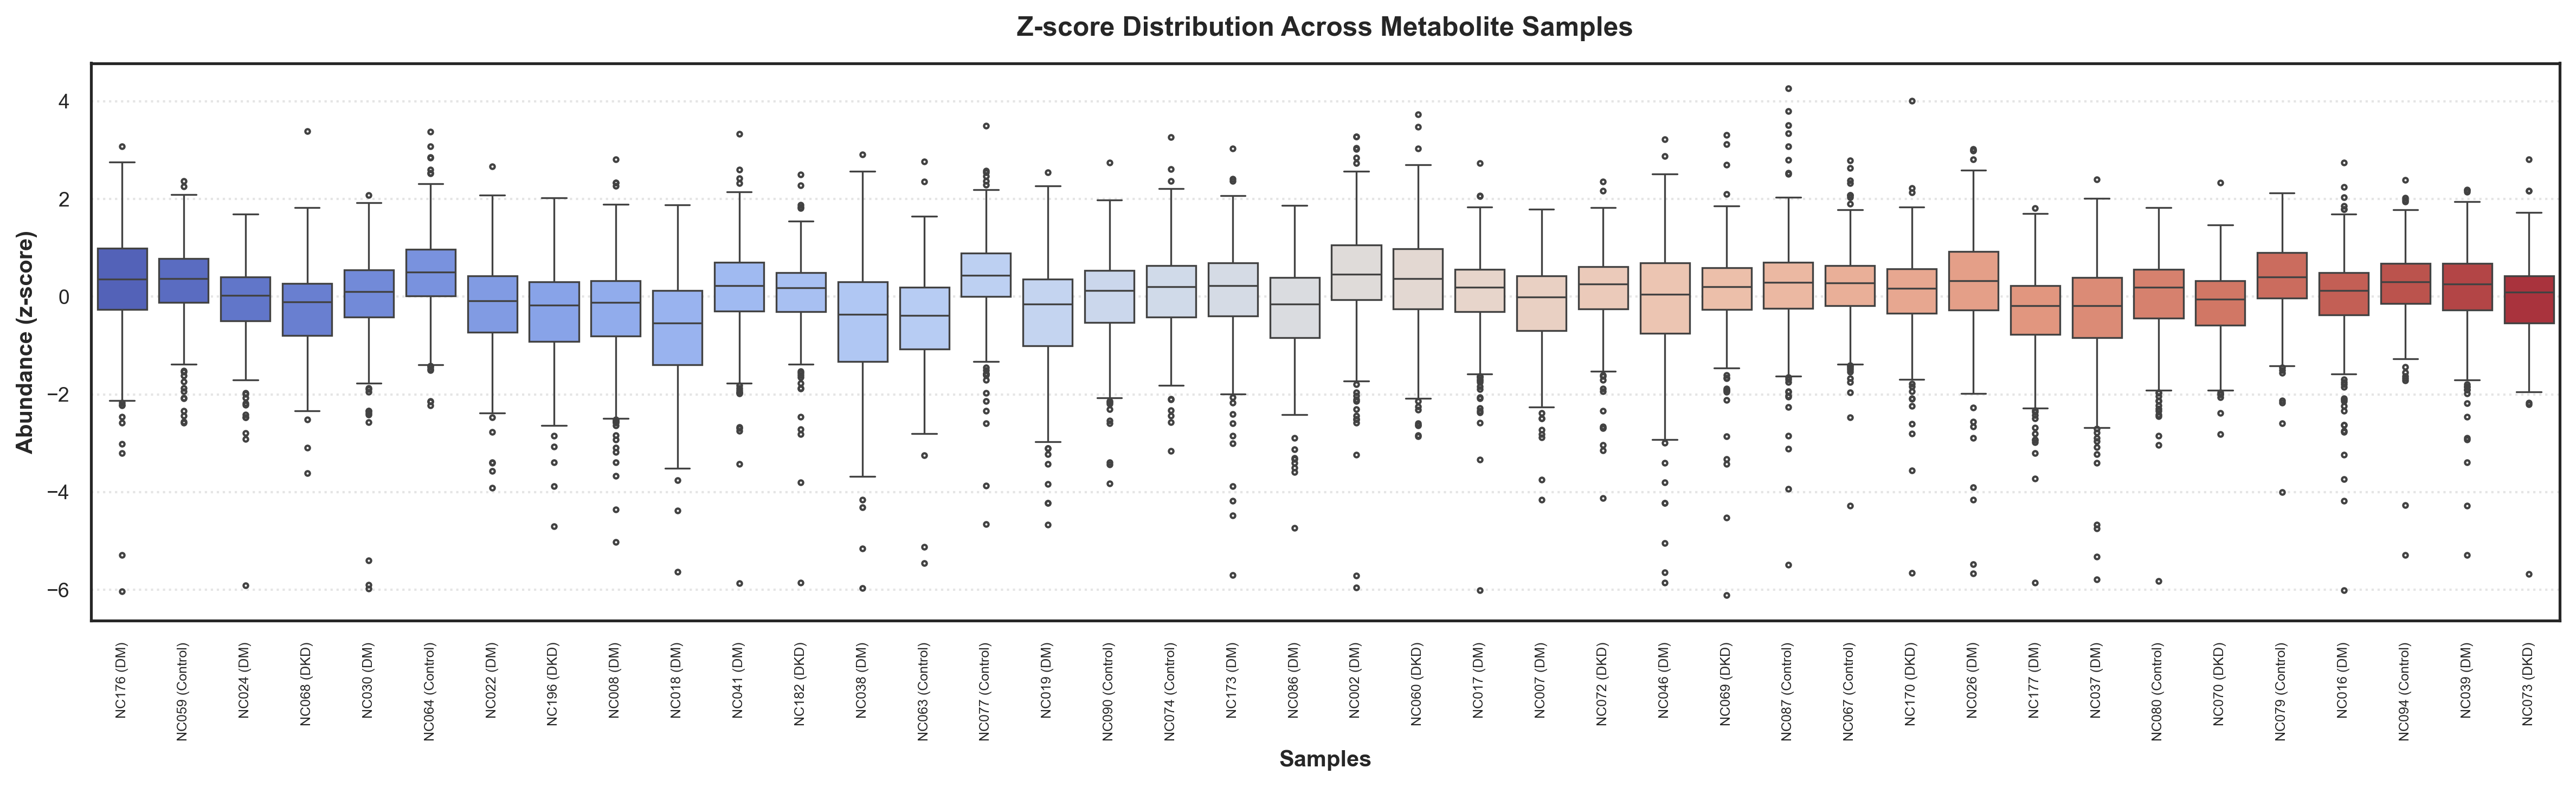

Performing differential expression (Welch's t-test: DKD vs Control)...
Generating Volcano plot (DKD vs Control)...


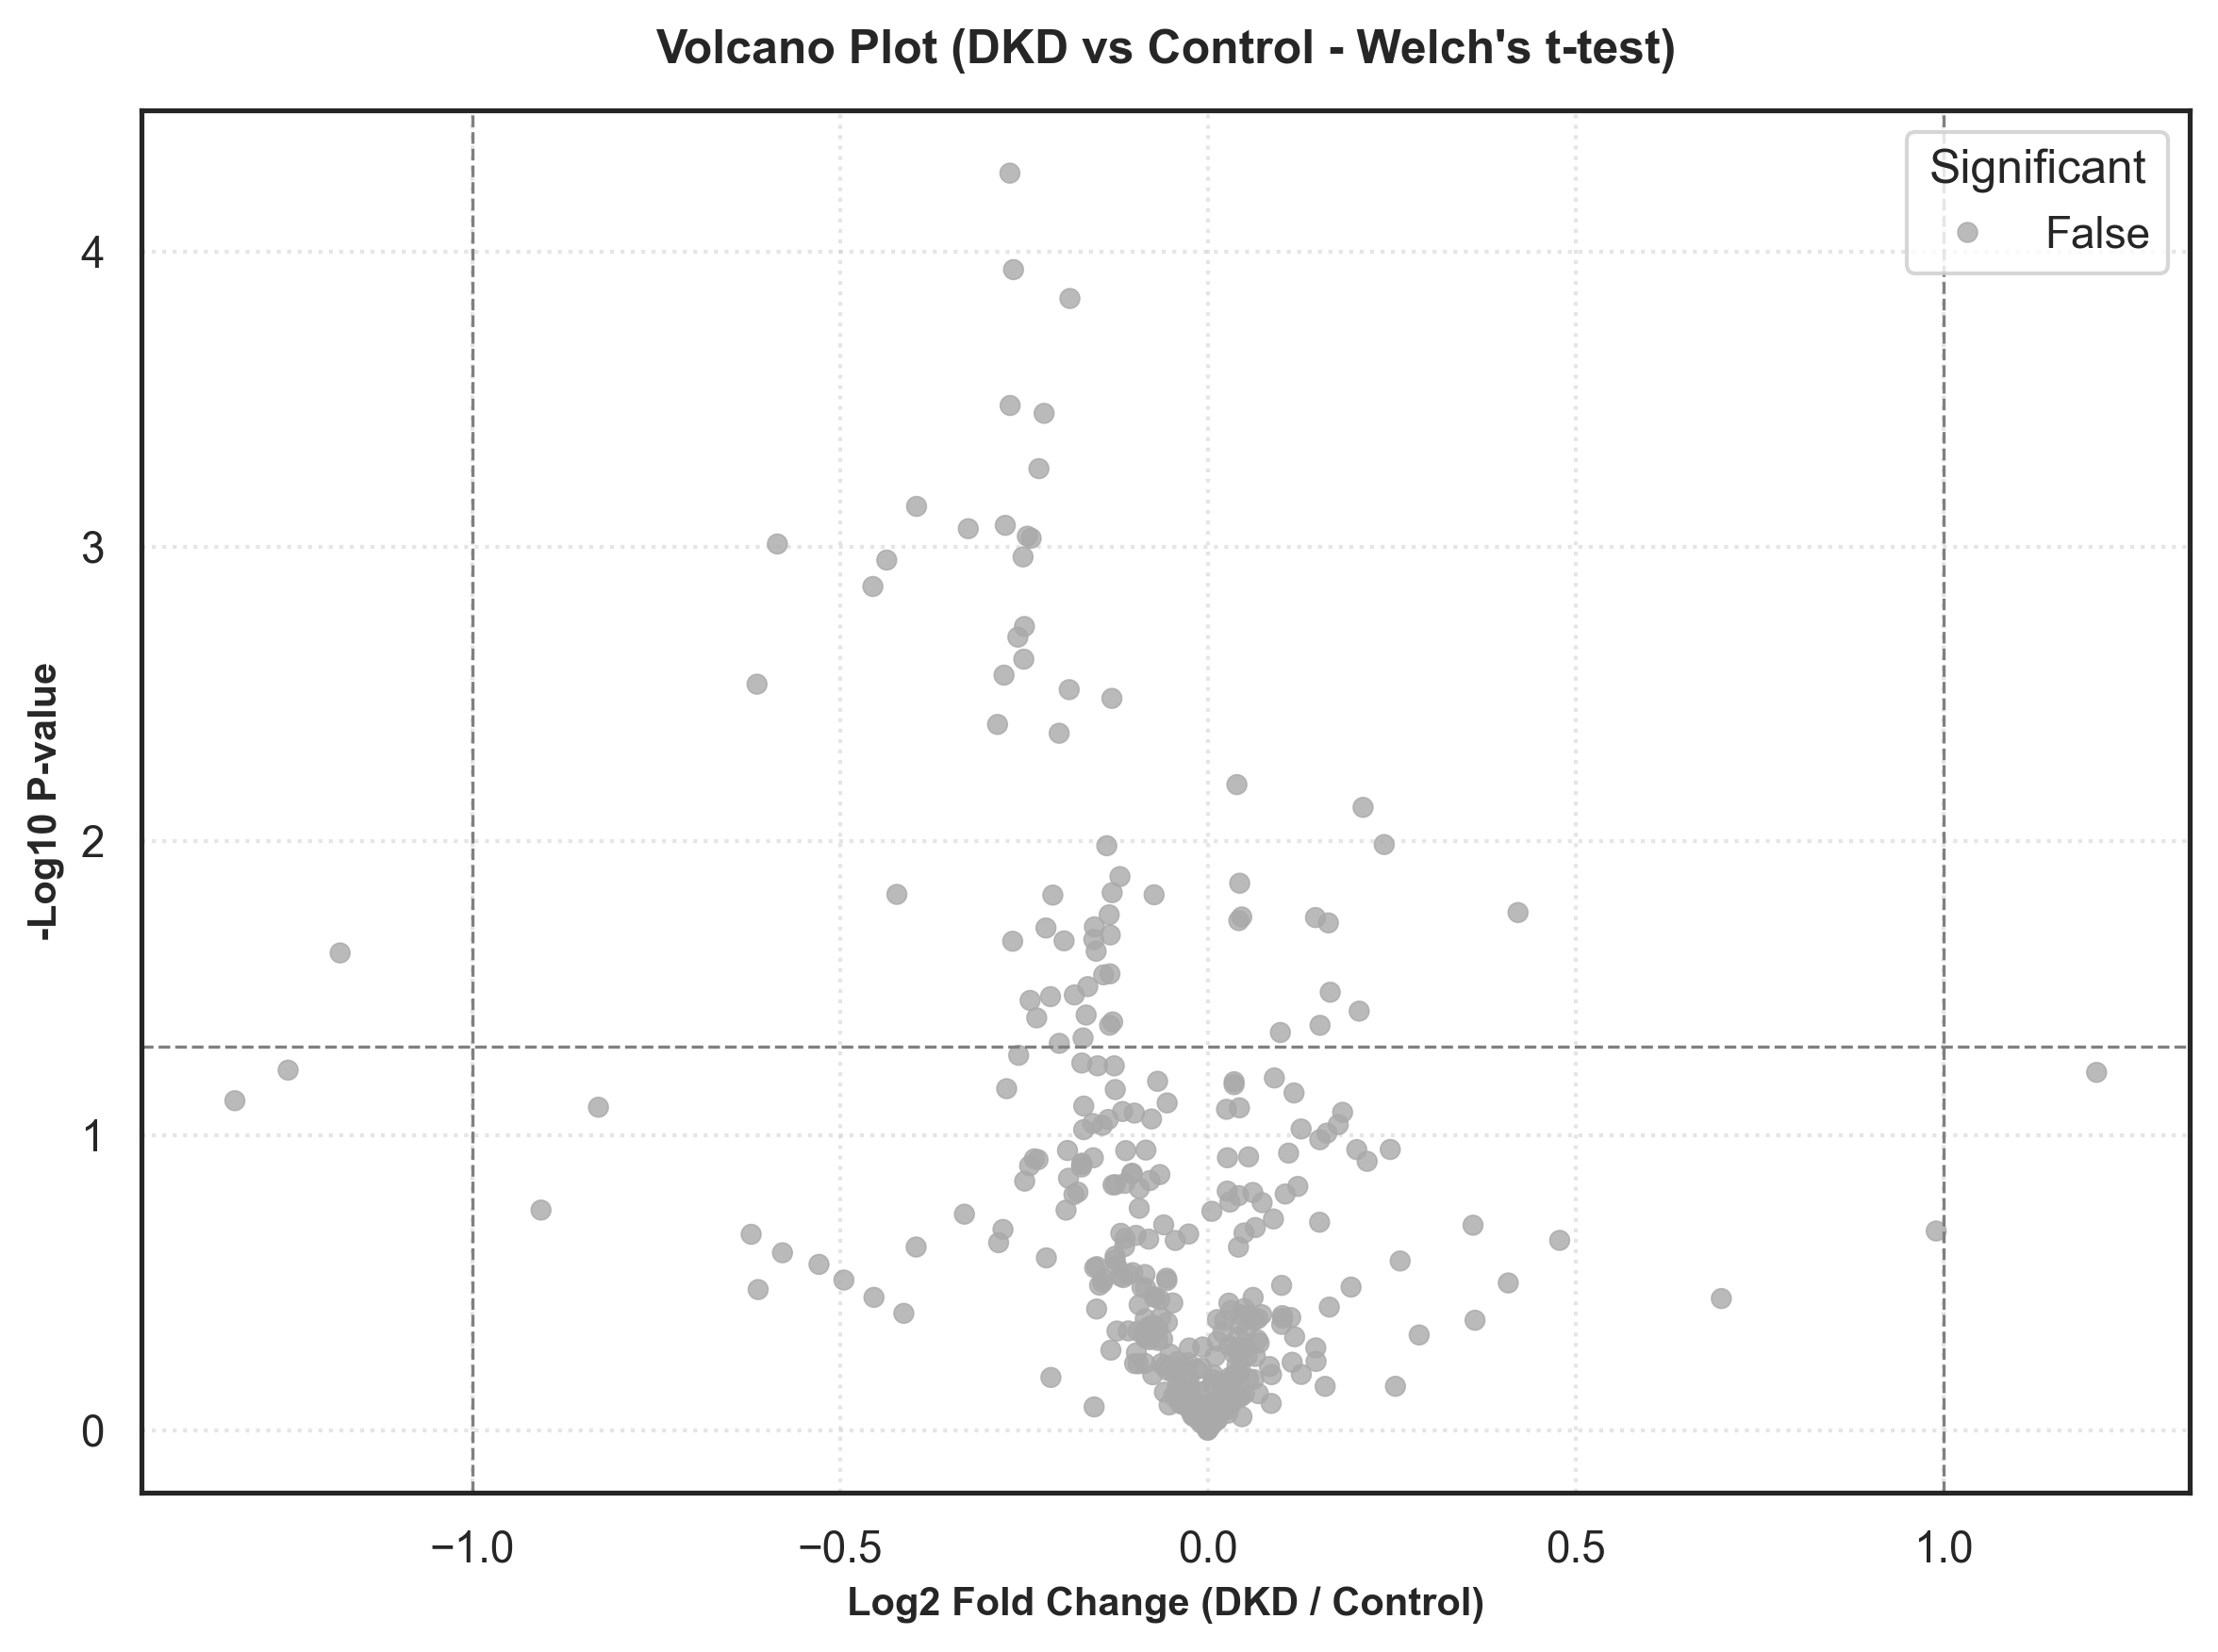

Running Sample-level PCA (3 conditions)...


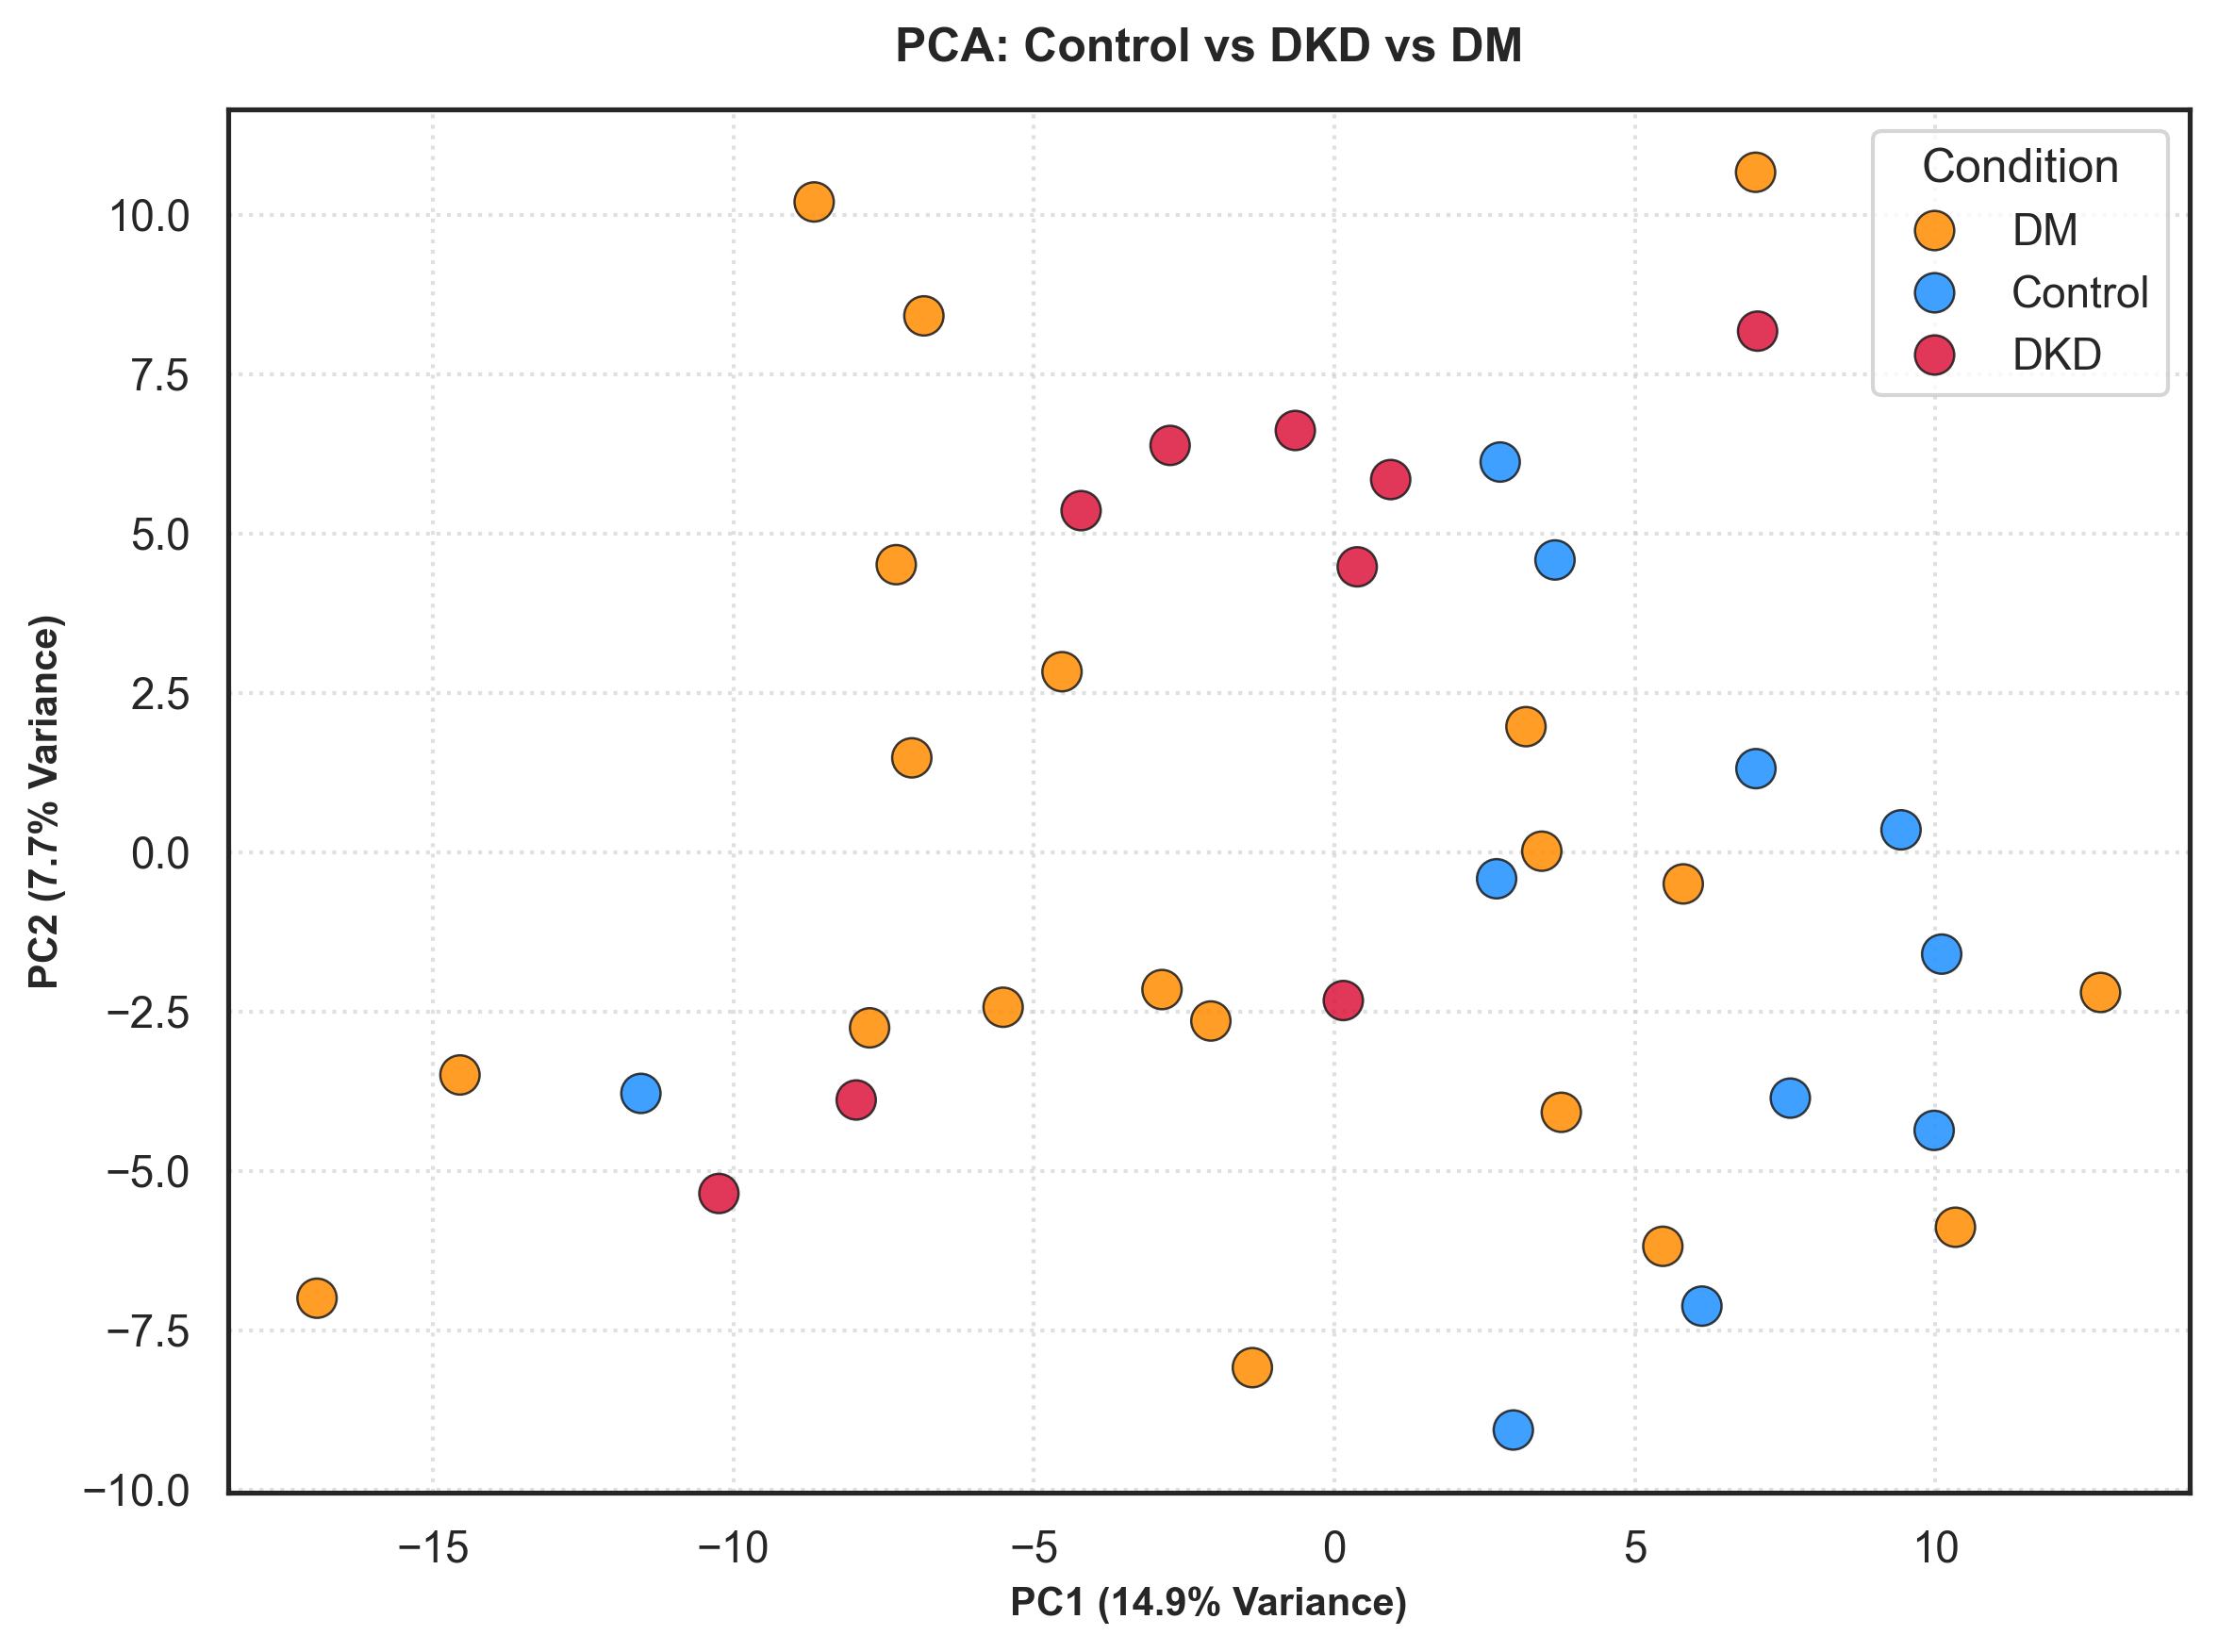

Running Metabolite-level PCA...


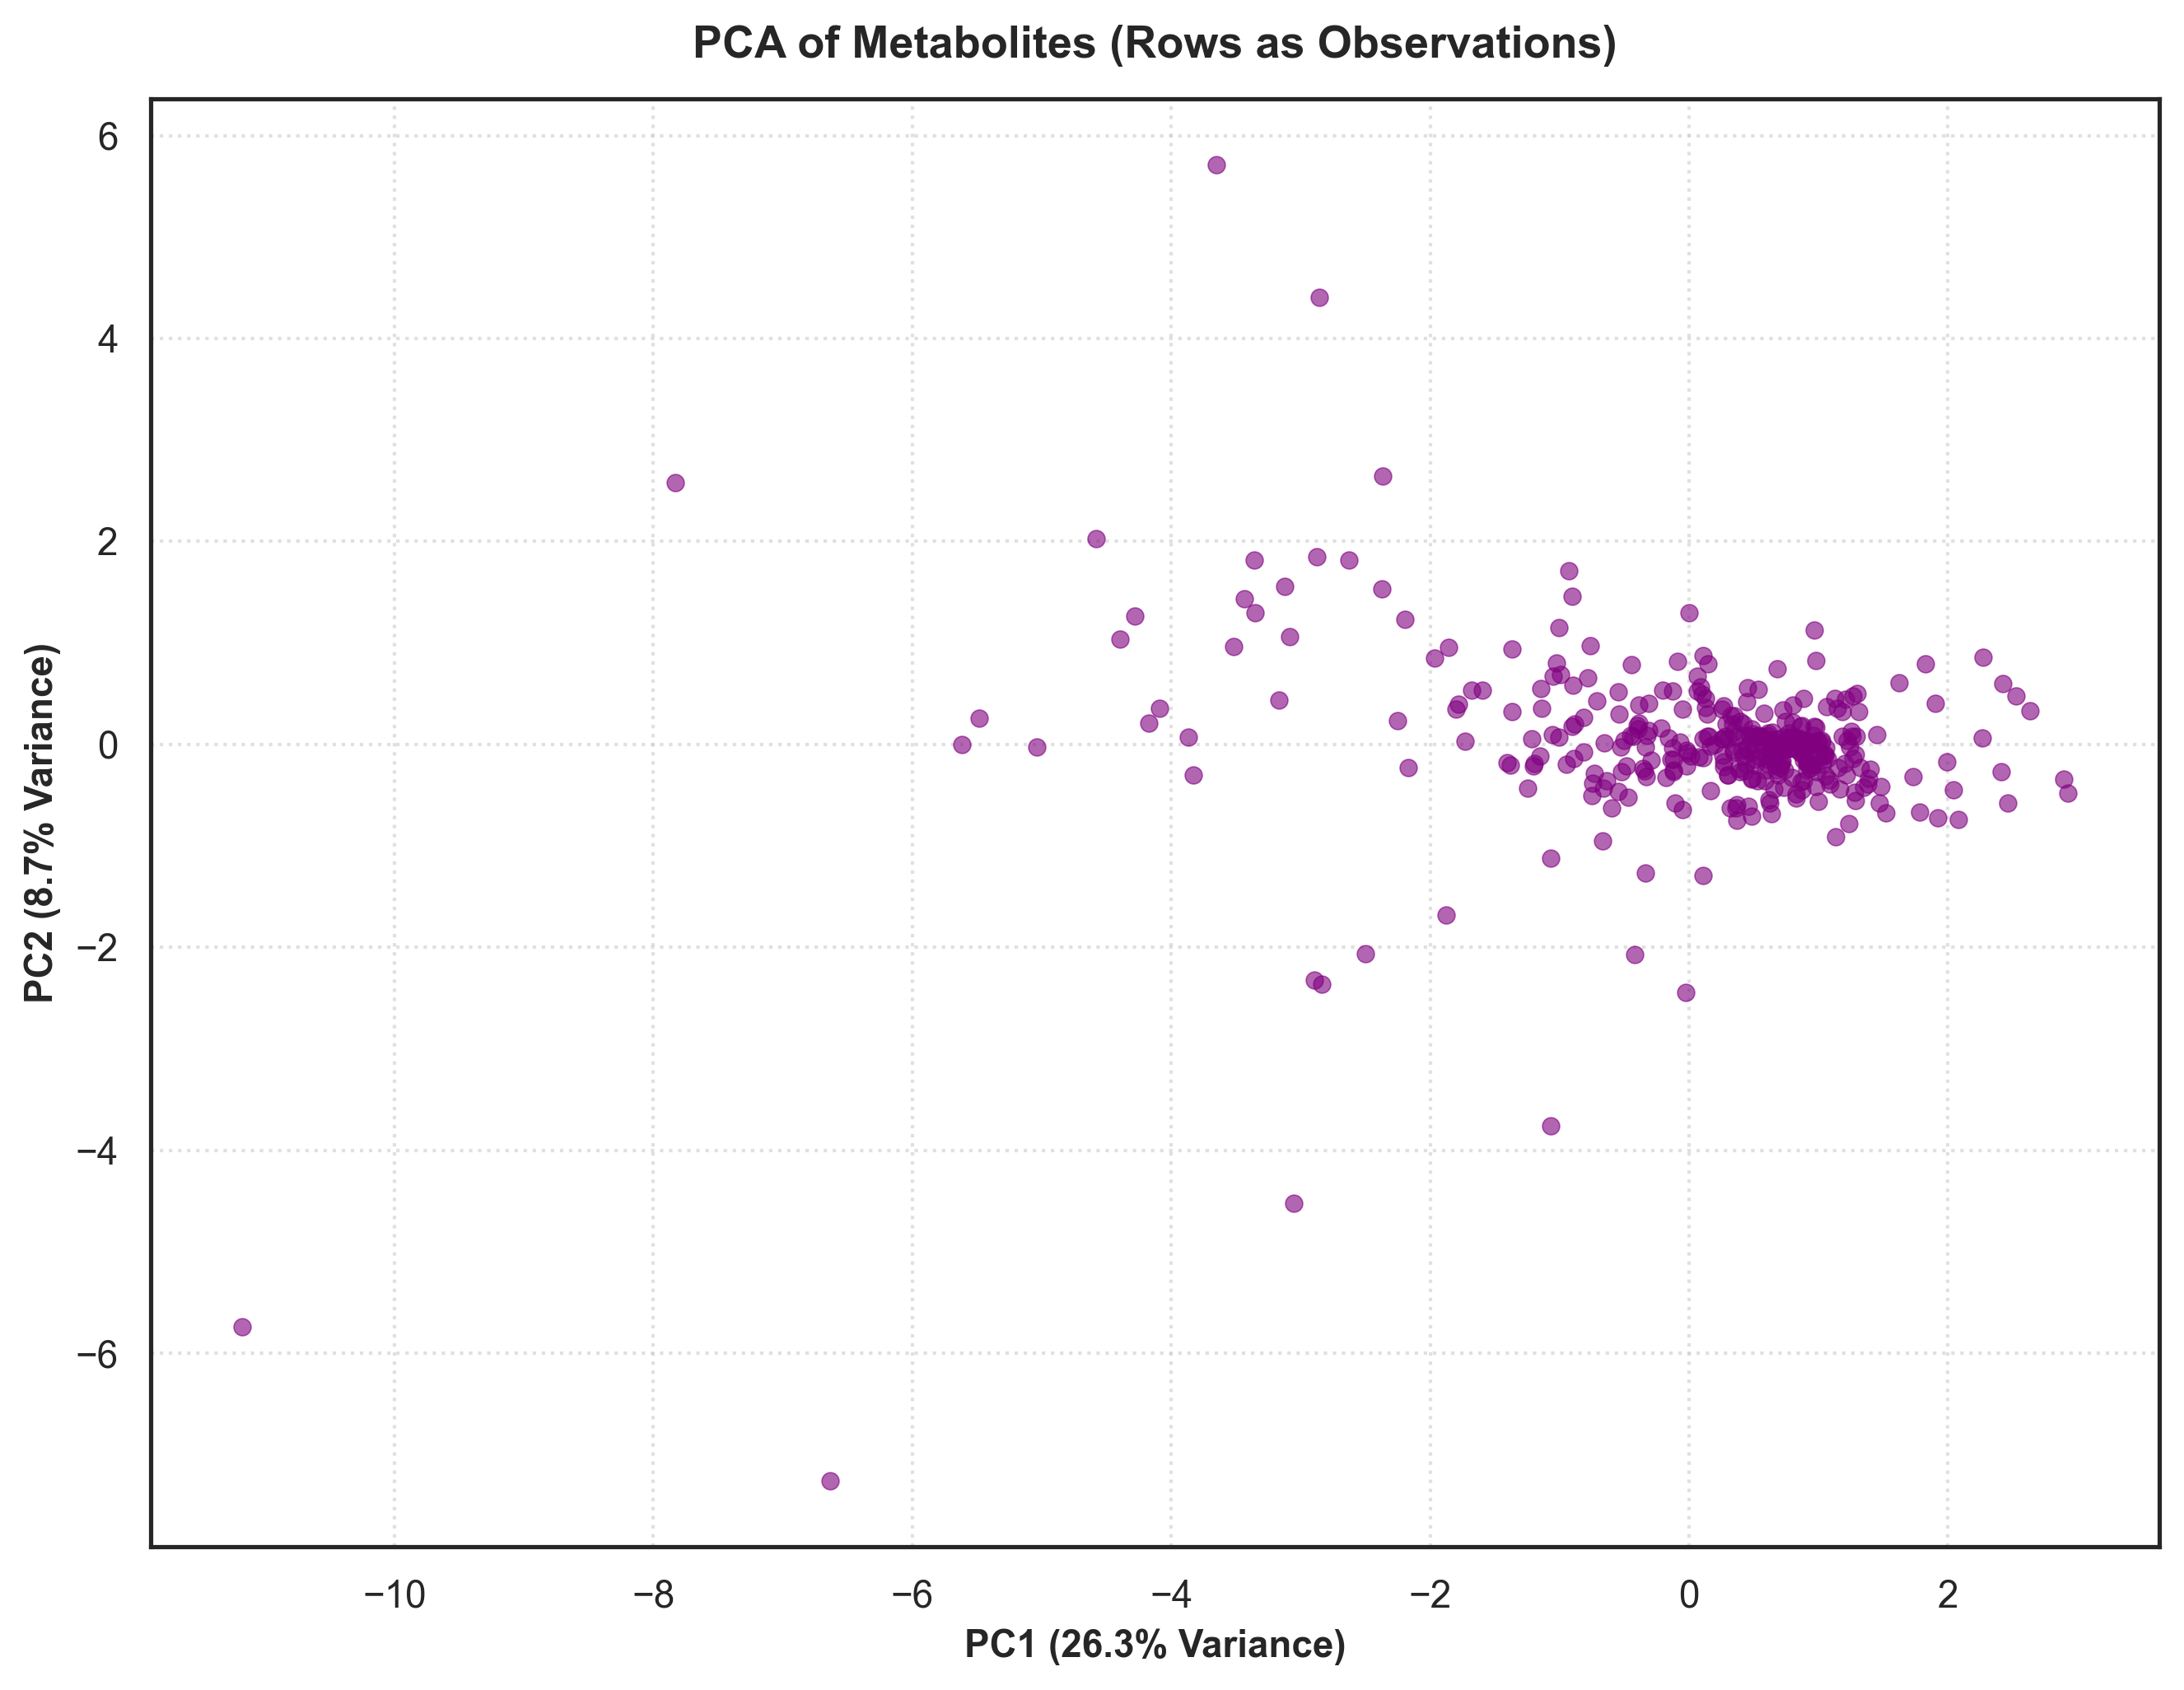

Running Sample-level UMAP (3 conditions)...


C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


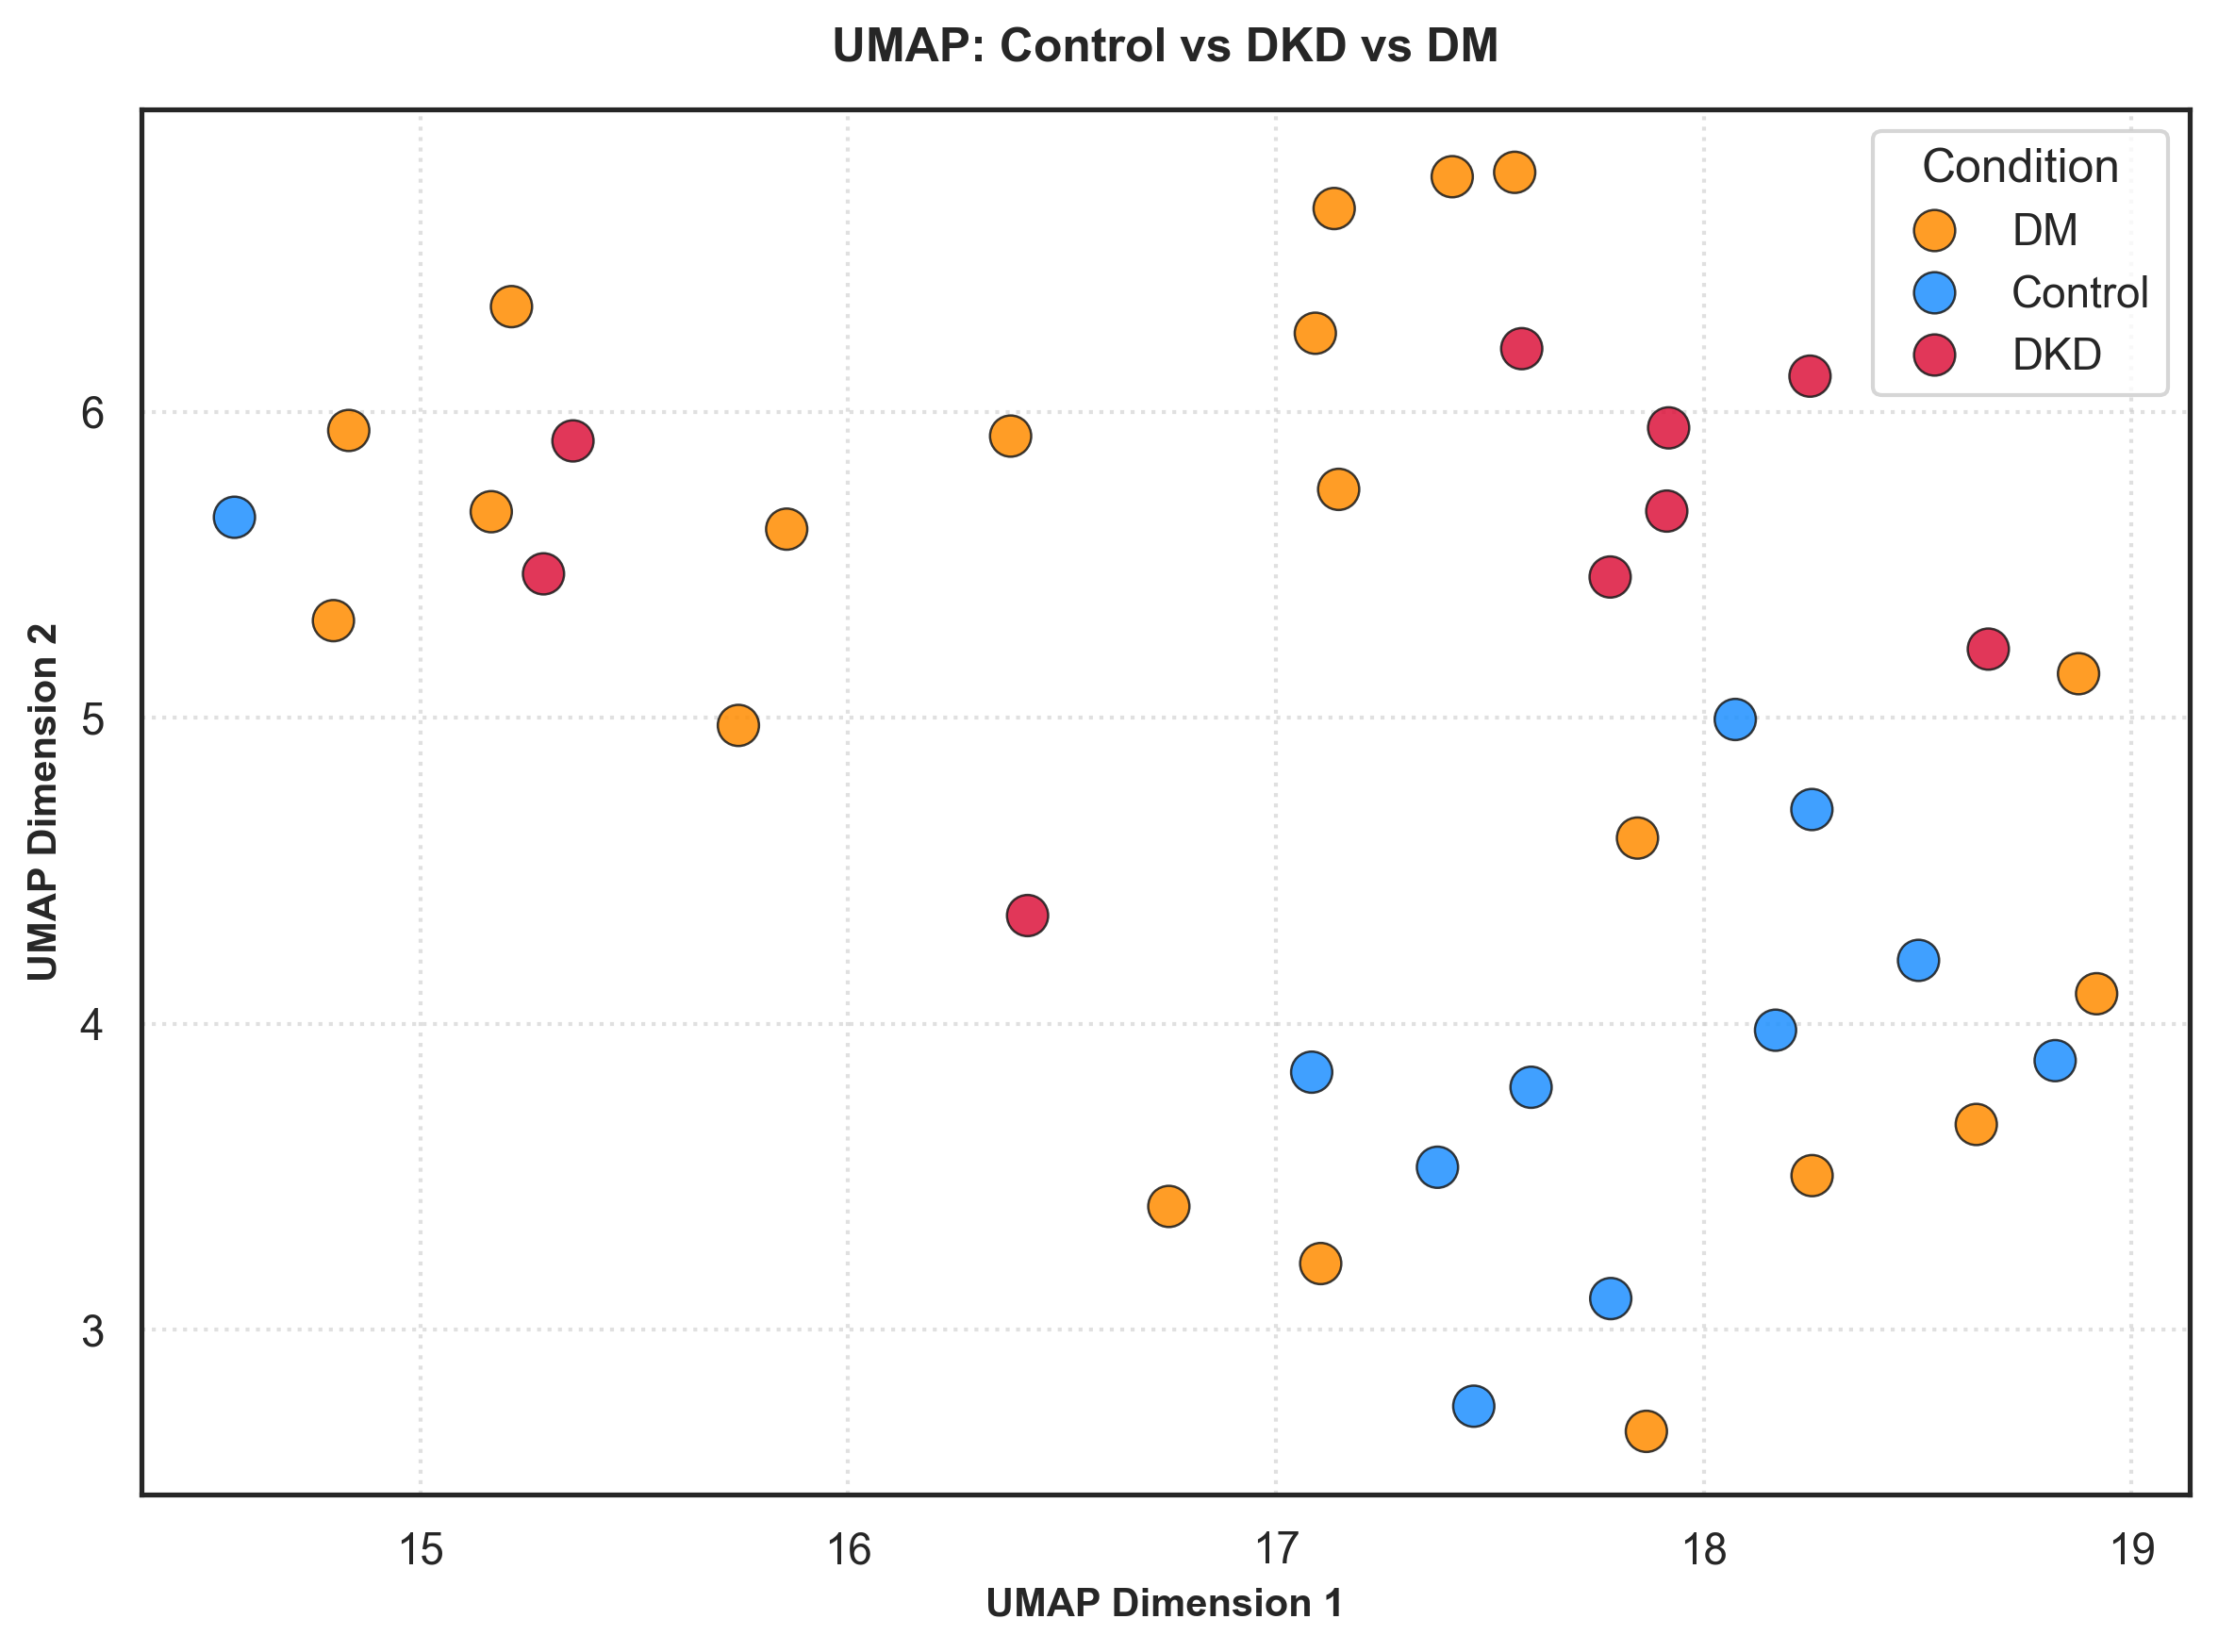

Running Metabolite-level UMAP...


C:\Users\Anas\AppData\Local\Programs\Python\Python310\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


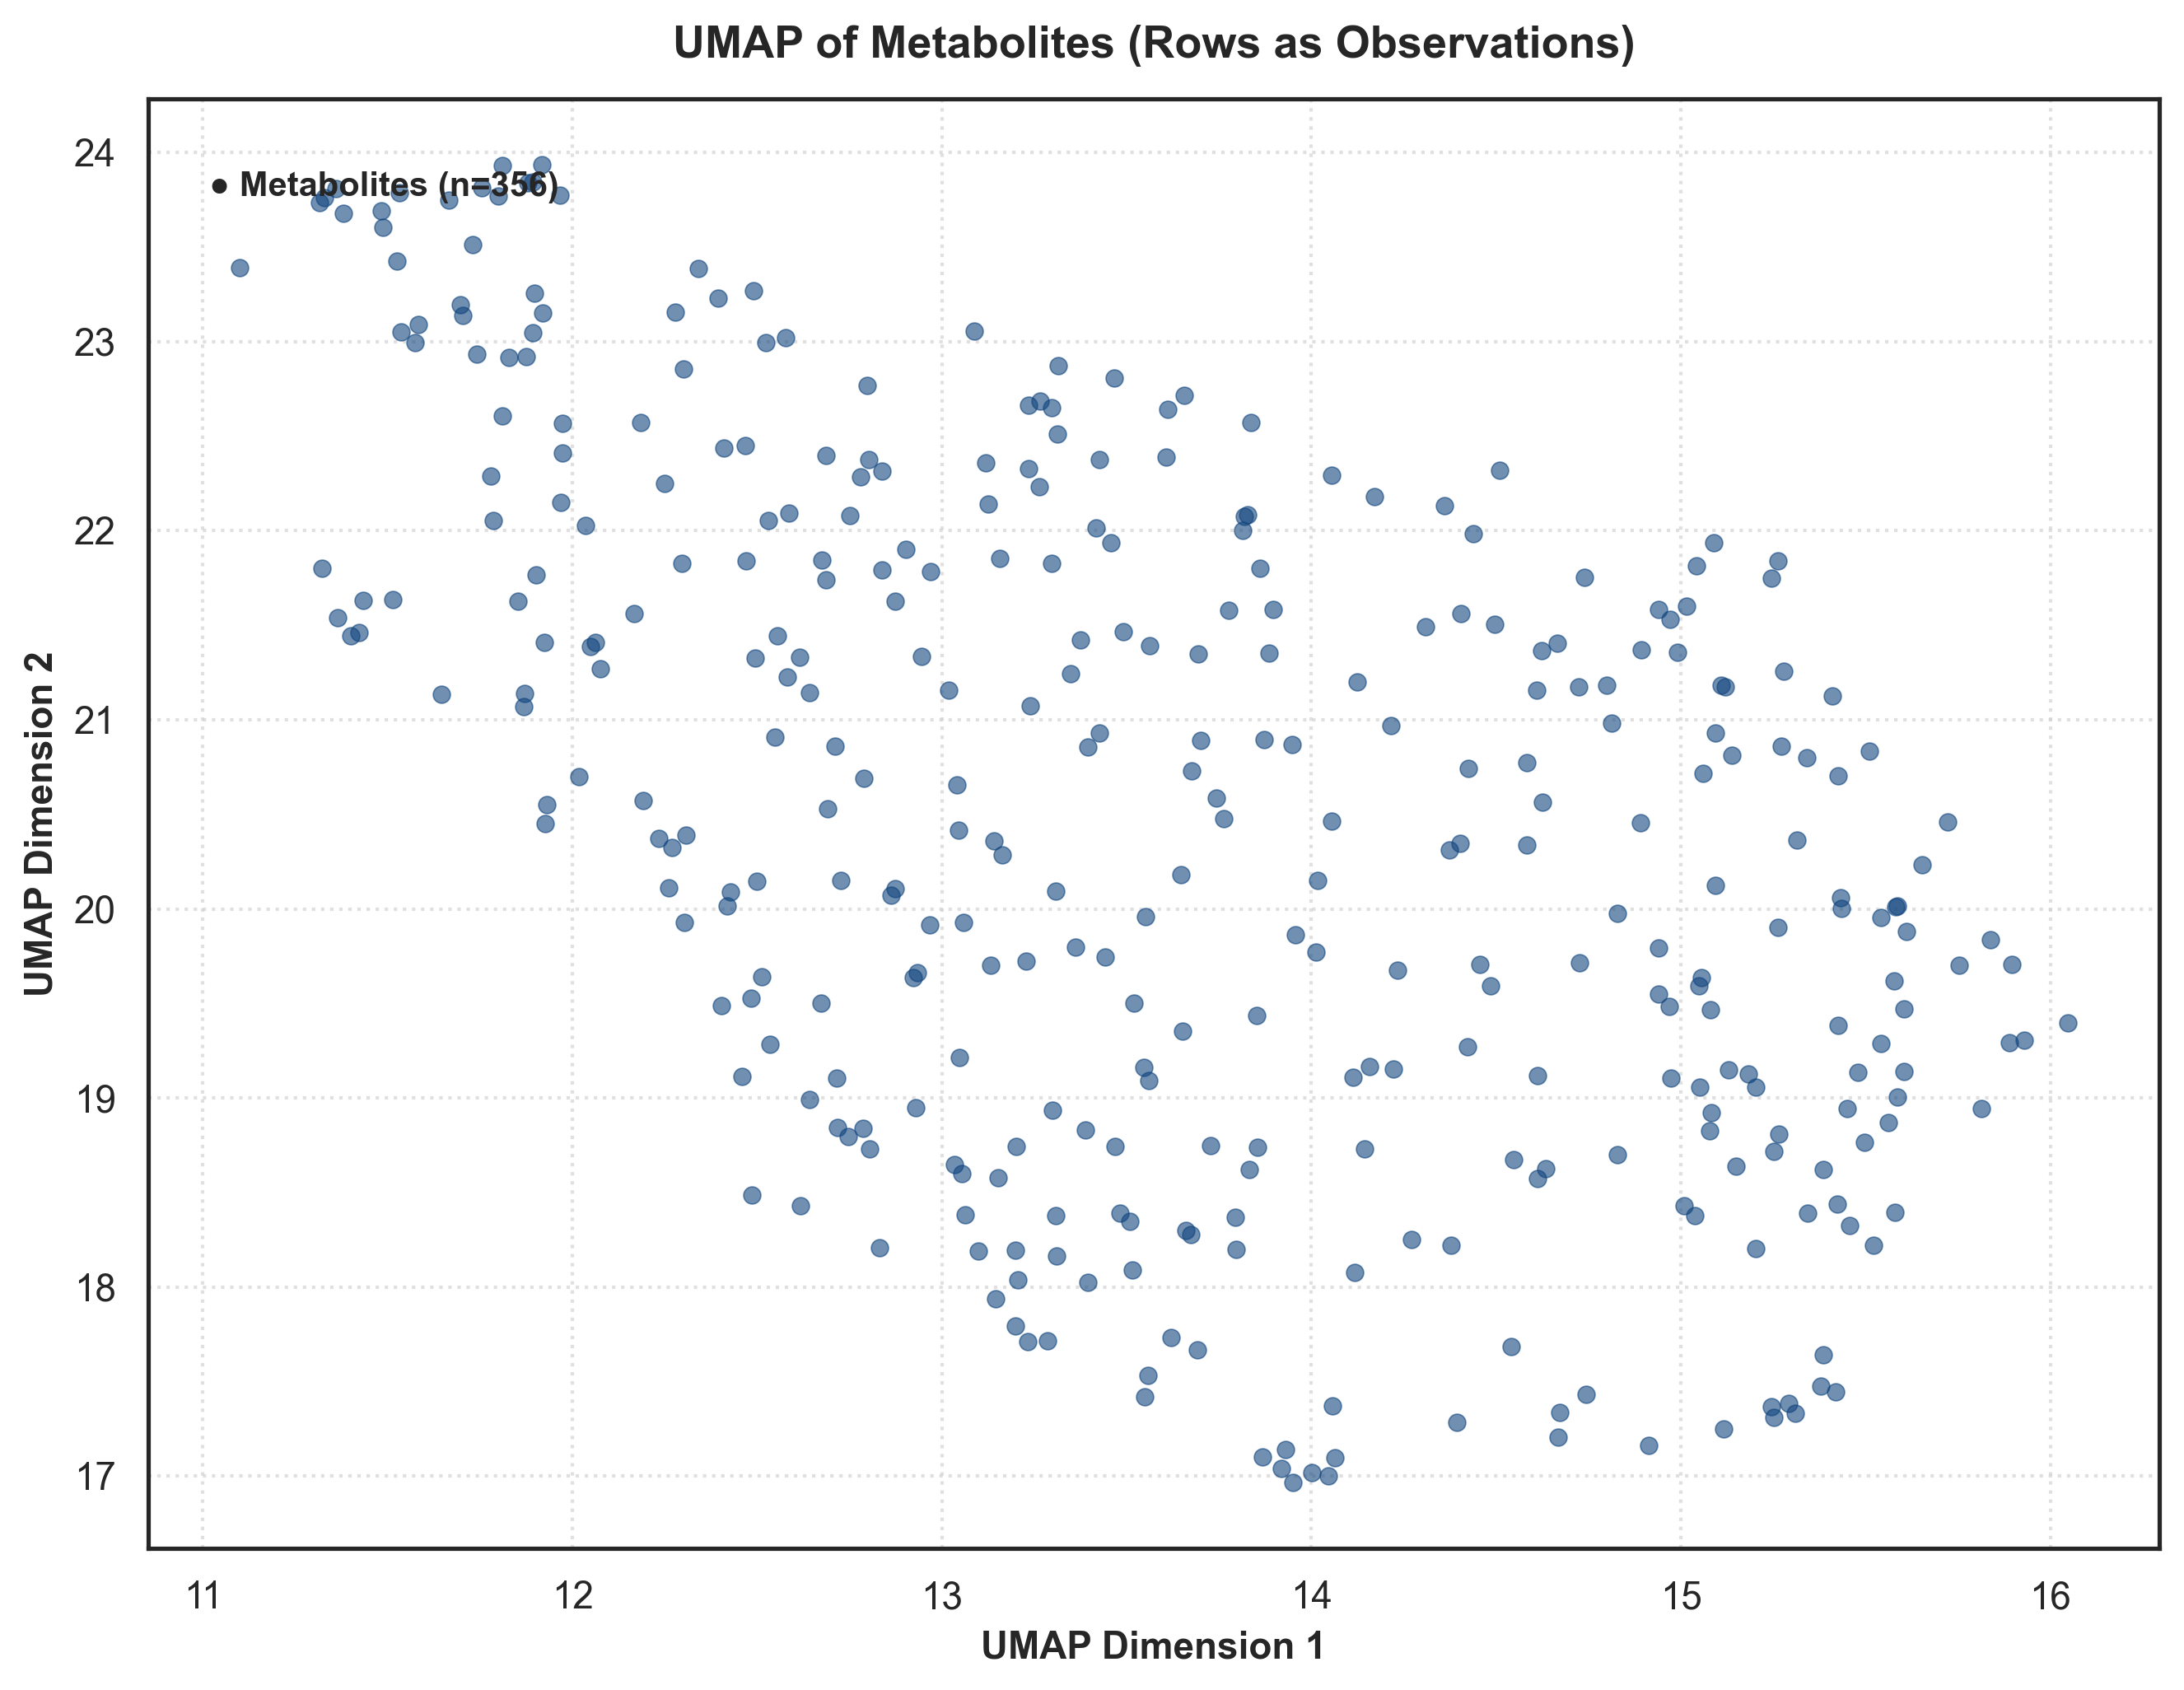

Generating Mean Abundance vs Variance plot (ProtBed parity)...


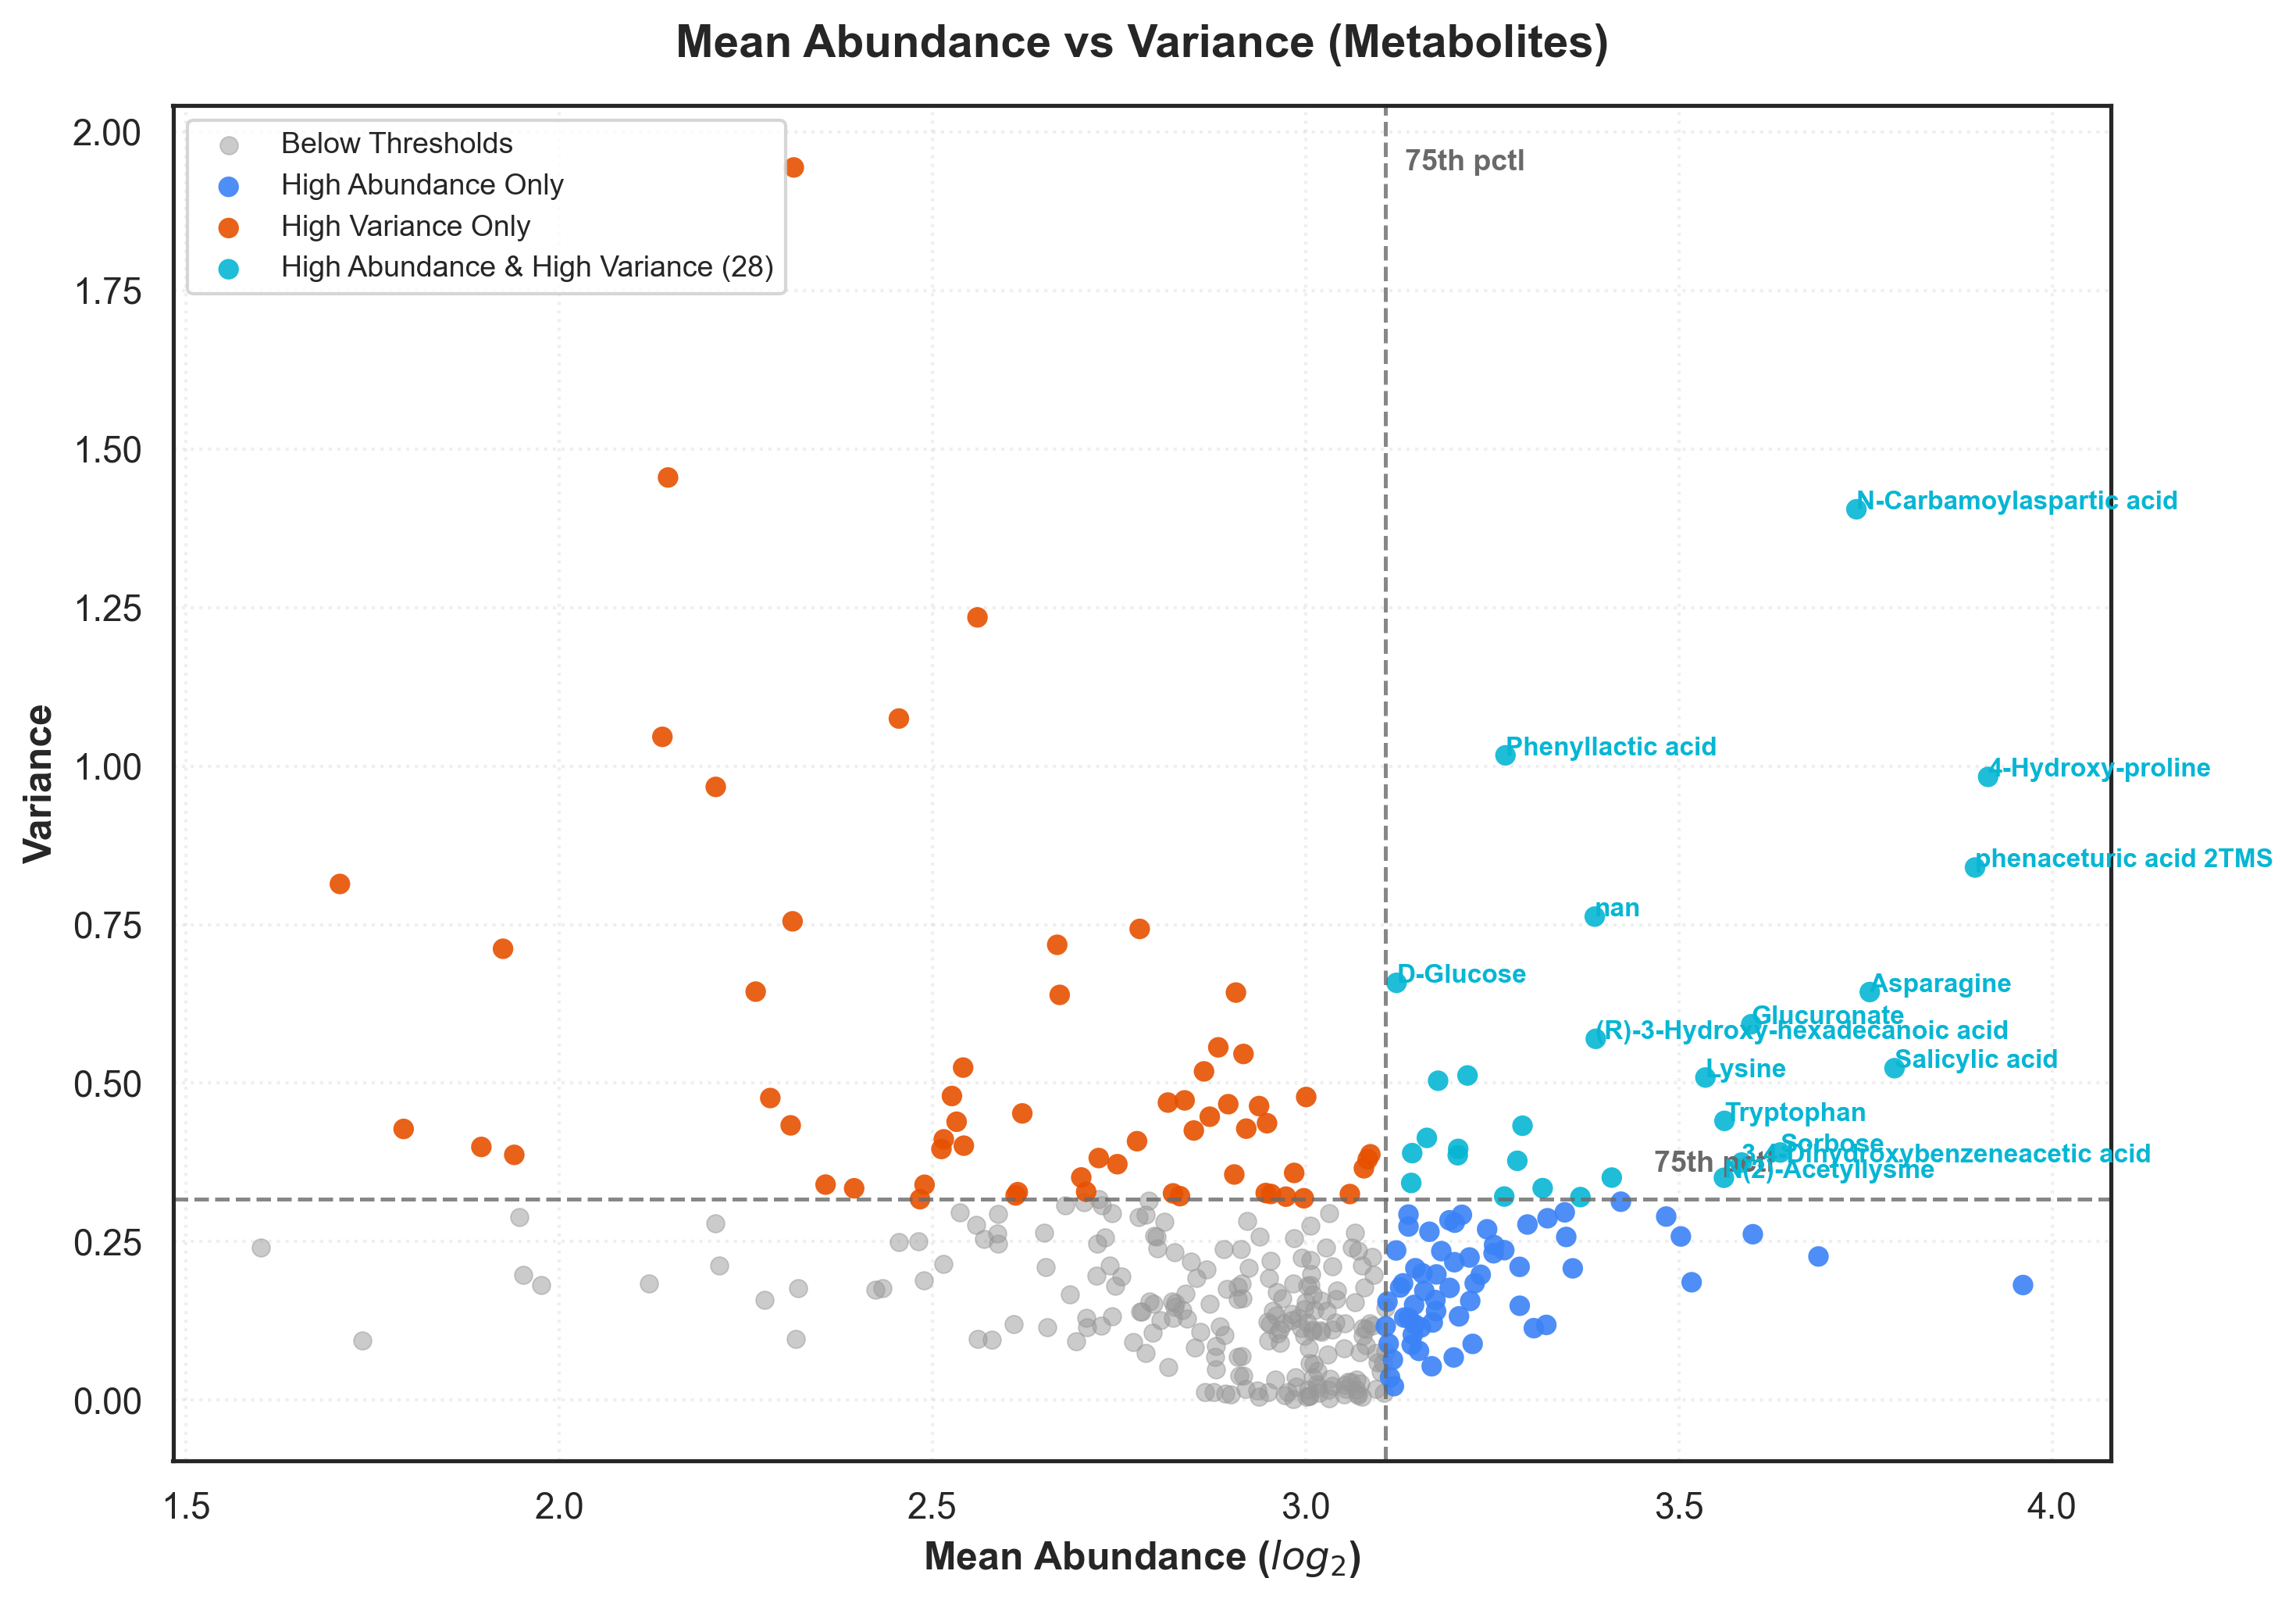

Running binary machine learning models (Predicting DKD vs Control)...
Generating sorted binary ROC curves (Predicting DKD vs Control)...


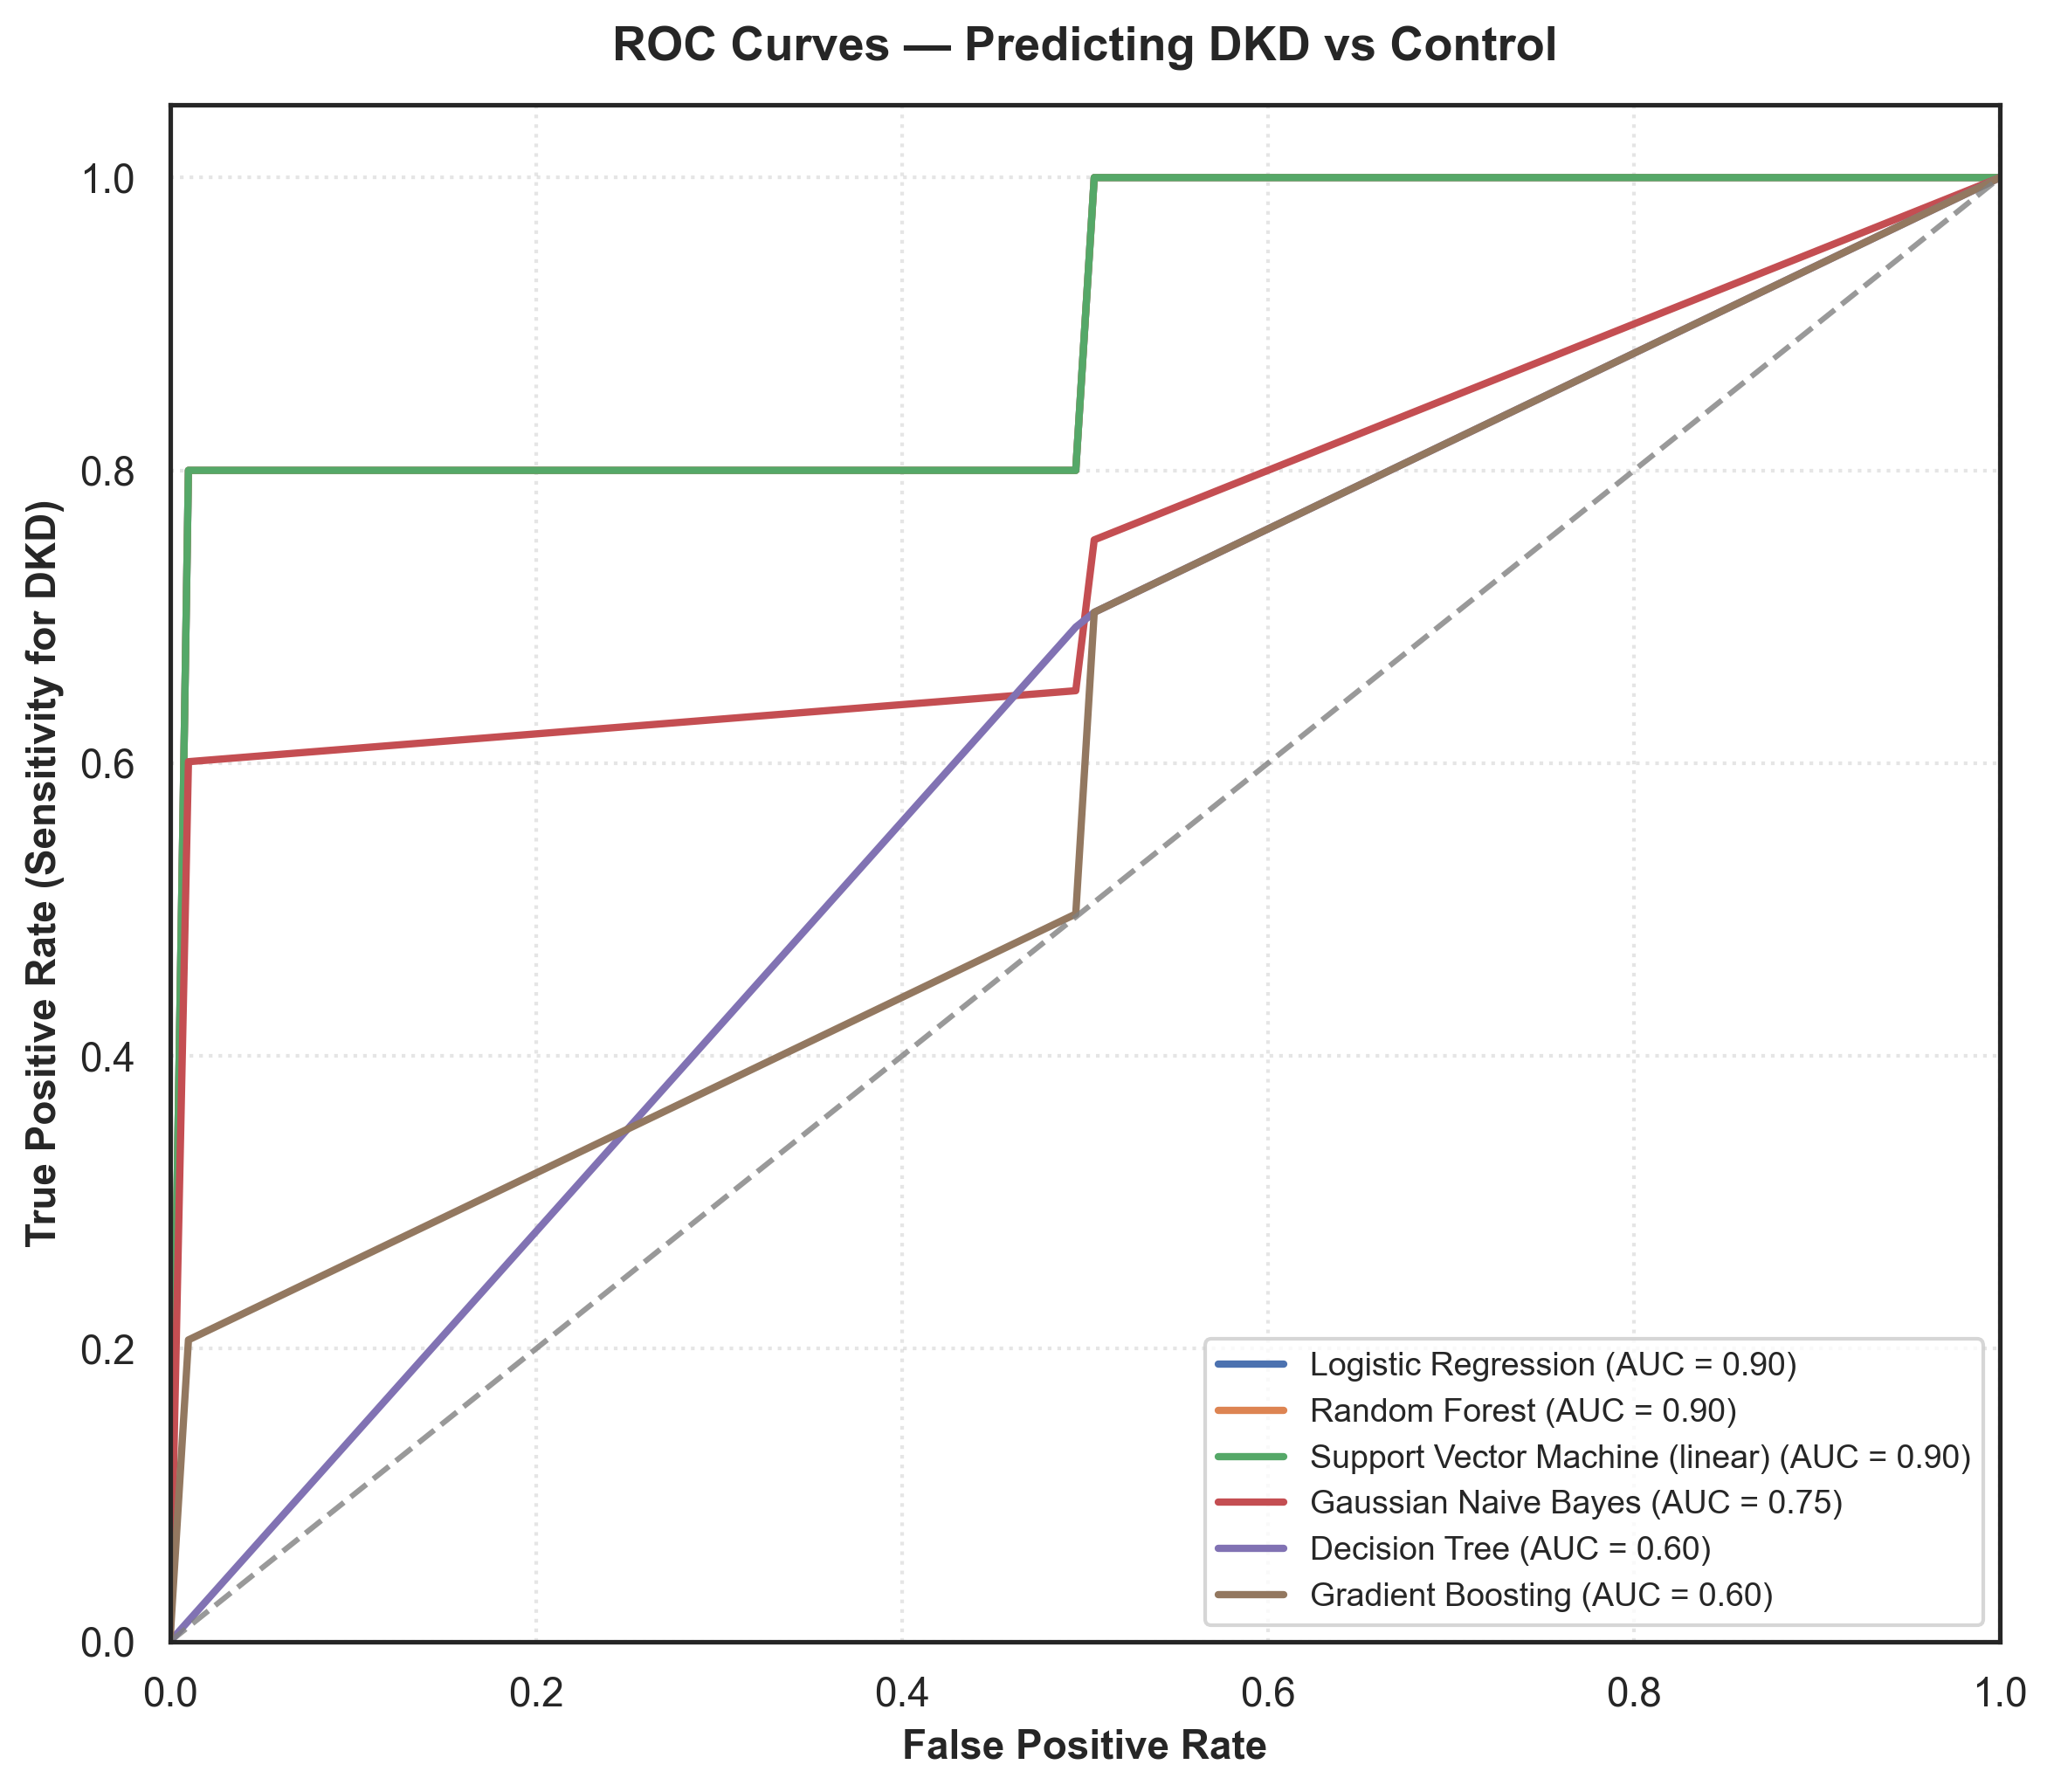

Generating Confusion Matrices...


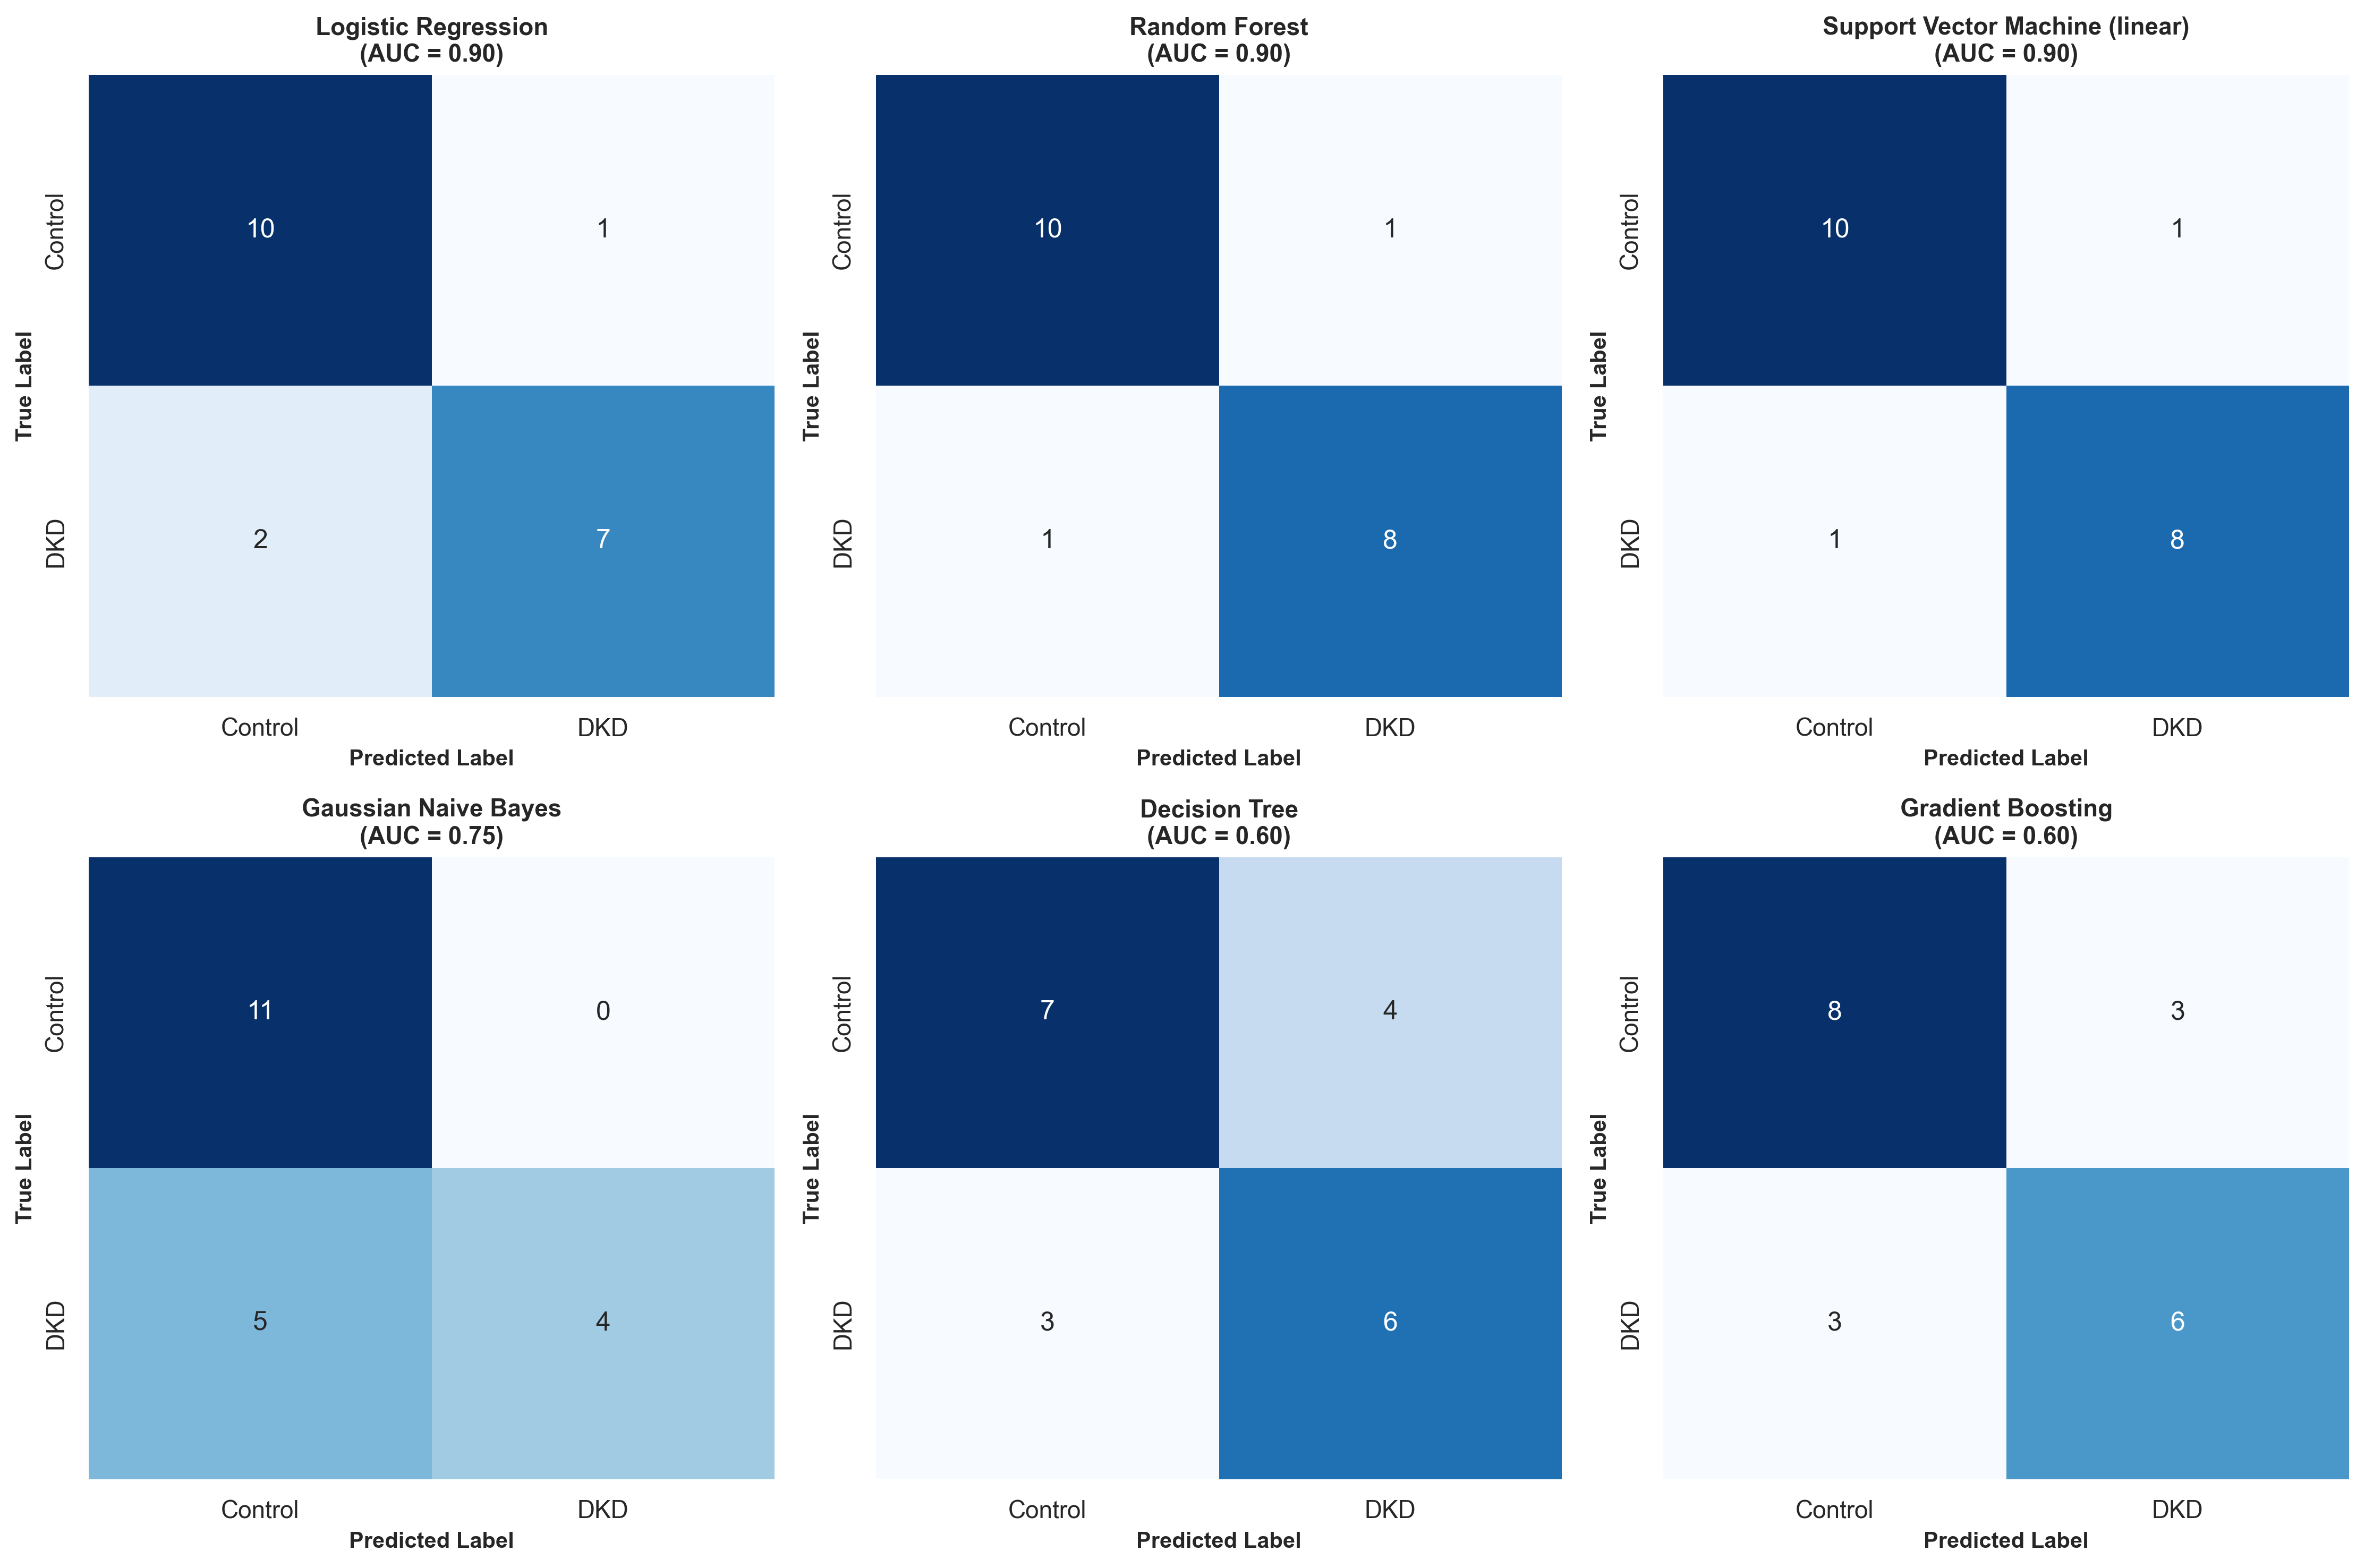


--- DKD vs Control Machine Learning Performance Summary ---
                          Model   AUC Accuracy Sensitivity Specificity    F1
            Logistic Regression 0.896    85.0%       77.8%       90.9% 0.824
                  Random Forest 0.896    90.0%       88.9%       90.9% 0.889
Support Vector Machine (linear) 0.896    90.0%       88.9%       90.9% 0.889
           Gaussian Naive Bayes 0.747    75.0%       44.4%      100.0% 0.615
                  Decision Tree 0.600    65.0%       66.7%       63.6% 0.632
              Gradient Boosting 0.599    70.0%       66.7%       72.7% 0.667

All metabolomics pipeline outputs successfully saved in 'benchmarks/'.


In [7]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, auc, accuracy_score, f1_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
import umap

def run_custom_metabolomics_pipeline(file_path, output_dir="benchmarks"):
    os.makedirs(output_dir, exist_ok=True)
    
    print("Loading metabolomics data...")
    df = pd.read_csv(file_path)
    
    sample_cols = [c for c in df.columns if any(cond in c for cond in ['(Control)', '(DKD)', '(DM)'])]
    
    groups = []
    for col in sample_cols:
        if '(Control)' in col:
            groups.append('Control')
        elif '(DKD)' in col:
            groups.append('DKD')
        elif '(DM)' in col:
            groups.append('DM')
    
    control_cols = [c for c in sample_cols if '(Control)' in c]
    dkd_cols = [c for c in sample_cols if '(DKD)' in c]
    dm_cols = [c for c in sample_cols if '(DM)' in c]
    
    # 1. Handle Missing Values: Keep missing values as zero
    print("Keeping missing values as zero...")
    df[sample_cols] = df[sample_cols].fillna(0)
    
    # 2. Handle Redundant Compounds: Keep the one with the highest mean abundance across samples
    print("Handling redundant compounds (keeping highest mean abundance)...")
    name_col = 'Reported_Name' if 'Reported_Name' in df.columns else df.columns[0]
    df['temp_mean_abundance'] = df[sample_cols].mean(axis=1)
    df = df.sort_values(by='temp_mean_abundance', ascending=False)
    df_filtered = df.drop_duplicates(subset=[name_col], keep='first').copy()
    df_filtered = df_filtered.drop(columns=['temp_mean_abundance'])

    # 3. Log2 transformation
    print("Applying Log2 transformation...")
    log2_data = np.log2(df_filtered[sample_cols].replace(0, np.nan))
    min_val = log2_data.min().min() if not log2_data.min().empty else 0
    log2_data = log2_data.fillna(min_val)

    # 4. Row-wise Z-score normalization
    row_mean = log2_data[sample_cols].mean(axis=1)
    row_std = log2_data[sample_cols].std(axis=1)
    z_row_wise = log2_data[sample_cols].sub(row_mean, axis=0).div(row_std, axis=0).fillna(0)

    print("Generating Z-score distribution boxplot...")
    plt.figure(figsize=(16, 5), dpi=300)
    sns.set_theme(style="white")
    sns.boxplot(data=z_row_wise, palette="coolwarm", fliersize=2, linewidth=0.8)
    plt.title("Z-score Distribution Across Metabolite Samples", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("Samples", fontsize=10, fontweight='bold')
    plt.ylabel("Abundance (z-score)", fontsize=10, fontweight='bold')
    plt.xticks(rotation=90, fontsize=6)
    plt.yticks(fontsize=9)
    plt.grid(axis='y', linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "zscore_distribution_metabolites.png"), dpi=300, bbox_inches='tight')
    plt.show()

    # 5. Volcano Plot (DKD vs Control using Welch's t-test)
    print("Performing differential expression (Welch's t-test: DKD vs Control)...")
    ctrl_mat = log2_data[control_cols].values
    dkd_mat = log2_data[dkd_cols].values
    
    p_values = []
    log2_fc = []
    for i in range(len(log2_data)):
        c_vals = ctrl_mat[i]
        d_vals = dkd_mat[i]
        stat, pval = ttest_ind(d_vals, c_vals, equal_var=False, nan_policy='omit')
        p_values.append(pval if not np.isnan(pval) else 1.0)
        log2_fc.append(np.mean(d_vals) - np.mean(c_vals))

    _, fdr_vals, _, _ = multipletests(p_values, method='fdr_bh')
    volcano_df = pd.DataFrame({
        'Compound': df_filtered[name_col].values,
        'Log2FC': log2_fc,
        'P-value': p_values,
        'FDR': fdr_vals
    })
    volcano_df['NegLog10P'] = -np.log10(volcano_df['P-value'].replace(0, 1e-300))
    volcano_df['Significant'] = (volcano_df['FDR'] < 0.05) & (volcano_df['Log2FC'].abs() > 1)

    print("Generating Volcano plot (DKD vs Control)...")
    plt.figure(figsize=(8, 6), dpi=300)
    sns.scatterplot(
        data=volcano_df, x='Log2FC', y='NegLog10P', hue='Significant',
        palette={True: 'crimson', False: 'darkgray'}, s=25, alpha=0.8, edgecolor=None
    )
    plt.axhline(-np.log10(0.05), color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(-1, color='grey', linestyle='--', linewidth=0.8)
    plt.axvline(1, color='grey', linestyle='--', linewidth=0.8)
    plt.title("Volcano Plot (DKD vs Control - Welch's t-test)", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("Log2 Fold Change (DKD / Control)", fontsize=10, fontweight='bold')
    plt.ylabel("-Log10 P-value", fontsize=10, fontweight='bold')
    plt.legend(title="Significant", loc='upper right', frameon=True)
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "volcano_plot_dkd_vs_control.png"), dpi=300, bbox_inches='tight')
    plt.show()

    # 6. Sample-level PCA (3 conditions)
    print("Running Sample-level PCA (3 conditions)...")
    X_samples = log2_data[sample_cols].T.values
    scaler = StandardScaler()
    X_samples_scaled = scaler.fit_transform(X_samples)
    
    pca_samples = PCA(n_components=2)
    sample_pcs = pca_samples.fit_transform(X_samples_scaled)
    sample_var = pca_samples.explained_variance_ratio_ * 100
    
    sample_pca_df = pd.DataFrame(data=sample_pcs, columns=['PC1', 'PC2'])
    sample_pca_df['Sample'] = sample_cols
    sample_pca_df['Group'] = groups

    plt.figure(figsize=(8, 6), dpi=300)
    sns.scatterplot(
        data=sample_pca_df, x='PC1', y='PC2', hue='Group',
        palette={'Control': 'dodgerblue', 'DKD': 'crimson', 'DM': 'darkorange'},
        s=100, alpha=0.85, edgecolor='k', linewidth=0.6
    )
    plt.title("PCA: Control vs DKD vs DM", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel(f"PC1 ({sample_var[0]:.1f}% Variance)", fontsize=10, fontweight='bold')
    plt.ylabel(f"PC2 ({sample_var[1]:.1f}% Variance)", fontsize=10, fontweight='bold')
    plt.legend(title='Condition', loc='best', frameon=True)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "pca_samples_metabolites.png"), dpi=300, bbox_inches='tight')
    plt.show()

    # 7. Metabolite-level PCA
    print("Running Metabolite-level PCA...")
    X_metabolites = log2_data[sample_cols].values.astype(float)
    pca_metabolites = PCA(n_components=2)
    metabolite_pcs = pca_metabolites.fit_transform(X_metabolites)
    metabolite_var = pca_metabolites.explained_variance_ratio_ * 100
    
    pca_meta_df = pd.DataFrame(data=metabolite_pcs, columns=['PC1', 'PC2'])
    pca_meta_df['Compound'] = df_filtered[name_col].values

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(data=pca_meta_df, x='PC1', y='PC2', alpha=0.6, s=25, color='purple', edgecolor=None)
    plt.title("PCA of Metabolites (Rows as Observations)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel(f"PC1 ({metabolite_var[0]:.1f}% Variance)", fontsize=11, fontweight='bold')
    plt.ylabel(f"PC2 ({metabolite_var[1]:.1f}% Variance)", fontsize=11, fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "pca_metabolites_space.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Running Sample-level UMAP (3 conditions)...")
    reducer_samples = umap.UMAP(n_neighbors=10, min_dist=0.1, random_state=42)
    umap_sample_emb = reducer_samples.fit_transform(X_samples_scaled)
    
    umap_sample_df = pd.DataFrame(data=umap_sample_emb, columns=['UMAP1', 'UMAP2'])
    umap_sample_df['Sample'] = sample_cols
    umap_sample_df['Group'] = groups

    plt.figure(figsize=(8, 6), dpi=300)
    sns.scatterplot(
        data=umap_sample_df, x='UMAP1', y='UMAP2', hue='Group',
        palette={'Control': 'dodgerblue', 'DKD': 'crimson', 'DM': 'darkorange'},
        s=110, alpha=0.85, edgecolor='k', linewidth=0.6
    )
    plt.title("UMAP: Control vs DKD vs DM", fontsize=12, fontweight='bold', pad=12)
    plt.xlabel("UMAP Dimension 1", fontsize=10, fontweight='bold')
    plt.ylabel("UMAP Dimension 2", fontsize=10, fontweight='bold')
    plt.legend(title='Condition', loc='best', frameon=True)
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "umap_samples_metabolites.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Running Metabolite-level UMAP...")
    reducer_metabolites = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=42)
    umap_meta_emb = reducer_metabolites.fit_transform(X_metabolites)
    
    umap_meta_df = pd.DataFrame(data=umap_meta_emb, columns=['UMAP1', 'UMAP2'])
    umap_meta_df['Compound'] = df_filtered[name_col].values

    plt.figure(figsize=(9, 7), dpi=300)
    sns.scatterplot(data=umap_meta_df, x='UMAP1', y='UMAP2', alpha=0.6, s=25, color='#11457E', edgecolor=None)
    plt.title("UMAP of Metabolites (Rows as Observations)", fontsize=13, fontweight='bold', pad=12)
    plt.xlabel("UMAP Dimension 1", fontsize=11, fontweight='bold')
    plt.ylabel("UMAP Dimension 2", fontsize=11, fontweight='bold')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.text(0.03, 0.95, f"● Metabolites (n={len(df_filtered)})", transform=plt.gca().transAxes, fontsize=10, fontweight='bold', verticalalignment='top')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "umap_metabolites_space.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Generating Mean Abundance vs Variance plot (ProtBed parity)...")
    means = []
    variances = []
    compound_names = df_filtered[name_col].tolist()

    for _, row in df_filtered[sample_cols].iterrows():
        vals = row.values.astype(float)
        valid_vals = vals[vals > 0]
        if len(valid_vals) == 0:
            valid_vals = np.array([0.0])
        
        if np.any(valid_vals > 50):
            log_vals = np.log2(valid_vals + 1.0)
        else:
            log_vals = valid_vals
            
        means.append(np.mean(log_vals))
        variances.append(np.var(log_vals, ddof=1) if len(log_vals) > 1 else 0.0)

    df_filtered['mean_ab'] = means
    df_filtered['var_ab'] = variances
    df_filtered['compound'] = compound_names

    sorted_means = np.sort(means)
    sorted_vars = np.sort(variances)
    n_feat = len(df_filtered)
    mean_thresh = sorted_means[int(np.floor(n_feat * 0.75))]
    var_thresh = sorted_vars[int(np.floor(n_feat * 0.75))]

    def assign_category(row):
        high_ab = row['mean_ab'] >= mean_thresh
        high_var = row['var_ab'] >= var_thresh
        if high_ab and high_var:
            return 'High Abundance & High Variance'
        elif high_ab:
            return 'High Abundance Only'
        elif high_var:
            return 'High Variance Only'
        return 'Below Thresholds'

    df_filtered['category'] = df_filtered.apply(assign_category, axis=1)
    high_high_count = (df_filtered['category'] == 'High Abundance & High Variance').sum()

    palette = {
        'Below Thresholds': '#999999',
        'High Abundance Only': '#3B82F6',
        'High Variance Only': '#E65100',
        'High Abundance & High Variance': '#06B6D4'
    }

    plt.figure(figsize=(10, 7), dpi=300)
    sns.scatterplot(
        data=df_filtered[df_filtered['category'] == 'Below Thresholds'],
        x='mean_ab', y='var_ab', color='#999999', s=30, alpha=0.5, edgecolor=None, label='Below Thresholds'
    )
    for cat in ['High Abundance Only', 'High Variance Only', 'High Abundance & High Variance']:
        subset = df_filtered[df_filtered['category'] == cat]
        lbl = f'{cat} ({len(subset)})' if cat == 'High Abundance & High Variance' else cat
        sns.scatterplot(
            data=subset, x='mean_ab', y='var_ab', color=palette[cat], s=40, alpha=0.9, edgecolor='none', label=lbl
        )

    plt.axvline(mean_thresh, color='dimgrey', linestyle='--', linewidth=1.2, alpha=0.8)
    plt.axhline(var_thresh, color='dimgrey', linestyle='--', linewidth=1.2, alpha=0.8)

    y_lim = plt.ylim()
    x_lim = plt.xlim()
    plt.text(mean_thresh + (x_lim[1] - x_lim[0]) * 0.01, y_lim[1] * 0.95, '75th pctl', color='dimgrey', fontsize=9, fontweight='bold')
    plt.text(x_lim[1] * 0.85, var_thresh + (y_lim[1] - y_lim[0]) * 0.02, '75th pctl', color='dimgrey', fontsize=9, fontweight='bold')

    top15 = df_filtered[df_filtered['category'] == 'High Abundance & High Variance'].copy()
    top15['rank_score'] = top15['mean_ab'] + top15['var_ab']
    top15 = top15.sort_values('rank_score', ascending=False).head(15)

    texts = []
    for _, row in top15.iterrows():
        texts.append(plt.text(row['mean_ab'], row['var_ab'], str(row['compound']), fontsize=8, color='#06B6D4', weight='semibold'))

    try:
        from adjustText import adjust_text
        adjust_text(texts, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))
    except Exception:
        pass

    plt.title("Mean Abundance vs Variance (Metabolites)", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("Mean Abundance ($log_2$)", fontsize=12, fontweight='bold')
    plt.ylabel("Variance", fontsize=12, fontweight='bold')
    plt.legend(loc='upper left', frameon=True, fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.3)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "mean_abundance_vs_variance_metabolites.png"), dpi=300, bbox_inches='tight')
    plt.show()

    # 11. Binary Machine Learning Benchmarks & ROC Curves (Predicting DKD vs Control)
    print("Running binary machine learning models (Predicting DKD vs Control)...")
    binary_cols = control_cols + dkd_cols
    binary_groups = ['Control' if '(Control)' in c else 'DKD' for c in binary_cols]
    
    X_binary = log2_data[binary_cols].T.values
    X_binary_scaled = scaler.fit_transform(X_binary)
    y_binary = np.array([0 if 'Control' in g else 1 for g in binary_groups])

    models = {
        "Gradient Boosting": GradientBoostingClassifier(random_state=42),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(random_state=42),
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
        "Support Vector Machine (linear)": SVC(kernel='linear', probability=True, random_state=42),
        "Gaussian Naive Bayes": GaussianNB()
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    results = []
    model_cm_data = {}
    model_roc_data = {}
    mean_fpr = np.linspace(0, 1, 100)

    for name, model in models.items():
        y_true_fold = []
        y_pred_fold = []
        y_prob_fold = []
        fold_tprs = []

        for train_idx, test_idx in cv.split(X_binary_scaled, y_binary):
            X_train, X_test = X_binary_scaled[train_idx], X_binary_scaled[test_idx]
            y_train, y_test = y_binary[train_idx], y_binary[test_idx]

            model.fit(X_train, y_train)
            preds = model.predict(X_test)
            probs = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test)

            y_true_fold.extend(y_test)
            y_pred_fold.extend(preds)
            y_prob_fold.extend(probs)

            fpr, tpr, _ = roc_curve(y_test, probs)
            fold_tprs.append(np.interp(mean_fpr, fpr, tpr))
            fold_tprs[-1][0] = 0.0

        y_true_fold = np.array(y_true_fold)
        y_pred_fold = np.array(y_pred_fold)
        y_prob_fold = np.array(y_prob_fold)

        acc = accuracy_score(y_true_fold, y_pred_fold)
        f1 = f1_score(y_true_fold, y_pred_fold, zero_division=0)
        cm = confusion_matrix(y_true_fold, y_pred_fold)
        
        tn, fp, fn, tp = cm.ravel() if cm.size == 4 else (0, 0, 0, 0)
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

        mean_tpr = np.mean(fold_tprs, axis=0)
        mean_tpr[-1] = 1.0
        mean_auc = auc(mean_fpr, mean_tpr)

        results.append({
            "Model": name,
            "AUC": mean_auc,
            "Accuracy": acc,
            "Sensitivity": sensitivity,
            "Specificity": specificity,
            "F1": f1
        })
        model_cm_data[name] = cm
        model_roc_data[name] = {"fpr": mean_fpr, "tpr": mean_tpr, "auc": mean_auc}

    results_df = pd.DataFrame(results).sort_values(by="AUC", ascending=False).reset_index(drop=True)

    print("Generating sorted binary ROC curves (Predicting DKD vs Control)...")
    plt.figure(figsize=(8, 7), dpi=300)
    for _, row in results_df.iterrows():
        name = row["Model"]
        mean_auc = row["AUC"]
        data = model_roc_data[name]
        plt.plot(data["fpr"], data["tpr"], label=f"{name} (AUC = {mean_auc:.2f})", lw=2)

    plt.plot([0, 1], [0, 1], linestyle='--', lw=1.5, color='grey', alpha=0.8)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel("False Positive Rate", fontsize=11, fontweight='bold')
    plt.ylabel("True Positive Rate (Sensitivity for DKD)", fontsize=11, fontweight='bold')
    plt.title("ROC Curves — Predicting DKD vs Control", fontsize=13, fontweight='bold', pad=12)
    plt.legend(loc="lower right", frameon=True, fontsize=9)
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "roc_curves_dkd_vs_control.png"), dpi=300, bbox_inches='tight')
    plt.show()

    print("Generating Confusion Matrices...")
    fig, axes = plt.subplots(2, 3, figsize=(15, 10), dpi=300)
    axes = axes.flatten()
    for idx, row in results_df.iterrows():
        name = row["Model"]
        cm = model_cm_data[name]
        ax = axes[idx]
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax, 
                    xticklabels=['Control', 'DKD'], yticklabels=['Control', 'DKD'])
        ax.set_title(f"{name}\n(AUC = {row['AUC']:.2f})", fontsize=11, fontweight='bold')
        ax.set_xlabel("Predicted Label", fontsize=10, fontweight='bold')
        ax.set_ylabel("True Label", fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, "confusion_matrices_dkd_control.png"), dpi=300, bbox_inches='tight')
    plt.show()

    formatted_df = results_df.copy()
    formatted_df["AUC"] = formatted_df["AUC"].map("{:.3f}".format)
    formatted_df["Accuracy"] = (formatted_df["Accuracy"] * 100).map("{:.1f}%".format)
    formatted_df["Sensitivity"] = (formatted_df["Sensitivity"] * 100).map("{:.1f}%".format)
    formatted_df["Specificity"] = (formatted_df["Specificity"] * 100).map("{:.1f}%".format)
    formatted_df["F1"] = formatted_df["F1"].map("{:.3f}".format)

    print("\n--- DKD vs Control Machine Learning Performance Summary ---")
    print(formatted_df.to_string(index=False))
    results_df.to_csv(os.path.join(output_dir, "dkd_vs_control_ml_summary.csv"), index=False)
    print(f"\nAll metabolomics pipeline outputs successfully saved in '{output_dir}/'.")

if __name__ == "__main__":
    run_custom_metabolomics_pipeline("data/Table_S3_Urine_Normalized_Clean_Metabolites_aaiag001.csv")